# Imports

In [114]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

# Variables

In [115]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [116]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']
aa_id = 0
rrs_id = 999999.0
max_score = 800
max_size = 1200
min_growth_score = 200
original_datafile_path = 'sqY2H_manual_automated_annotated_scores_size.csv'
tracking_dict = {}

# Single functions

In [117]:
def pull_numbers(df, verbose=False):
    df = pl.DataFrame(df)
    
    if 'per_well_integrated_intensity_gray' in df.columns:
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_null())
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_nan())
    
    if 'consensus_score' in df.columns:
        df = df.filter(pl.col('consensus_score').is_not_null())
        df = df.filter(pl.col('consensus_score').is_not_nan())
    
    dbs = df.select(pl.col('db_orf_id')).n_unique()
    ads = df.select(pl.col('ad_orf_id')).n_unique()
    
    df = df.with_columns(
        pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group"),
            pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    )
    
    muts = df.filter(pl.col('db_mut_id') != 0).select(pl.col('db_mut_id')).n_unique()
    
    if verbose:
        print('Number of rows:', df.height)
    
    return {'dbs': dbs, 'ads': ads, 'alleles': muts, 'edges': df.select(pl.col('edge_group')).n_unique(), 'ppis': df.select(pl.col('ppi_group')).n_unique()}

## Load original data

In [171]:
def load_original_dataframe(file_path, inputs_dir=inputs_dir, tracking_dict=tracking_dict):
    df = pd.read_csv(os.path.join(inputs_dir, file_path))
    
    # Create unique tracking ID
    df['unique_id'] = df.index
    
    # Initialize separate tracking dataframe
    tracking_df = df[['unique_id', 'ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch', 'manual_score_growth']].copy()
    tracking_df['status'] = 'Kept'
    tracking_df['reason'] = None
    
    # cast all to same format
    df['ad_orf_id'] = pd.to_numeric(df['ad_orf_id'], errors='coerce')
    df['db_orf_id'] = pd.to_numeric(df['db_orf_id'], errors='coerce')
    df['db_mut_id'] = pd.to_numeric(df['db_mut_id'], errors='coerce')
    
    # Drop conditions that are not used at all (LWA, LWAH1)
    conditions_to_drop = ['LWA', 'LWAH1']
    df = df[~df['condition_name'].isin(conditions_to_drop)]

    return df, tracking_dict, tracking_df


In [172]:
orig_df, tracking_dict, tracking_df = load_original_dataframe(file_path=original_datafile_path)

## Manual rescore

In [173]:
def update_manual_scores(input_df):
    rescore_folder = '/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/edgotyping_dropbox/large_data_files/experimental_data/sqY2H/plate_images/20251219_rescore'

    # find all .tsv files in the rescore_folder and subfolders
    rescore_files = []
    for root, dirs, files in os.walk(rescore_folder):
        for file in files:
            if file.endswith('.tsv'):
                rescore_files.append(os.path.join(root, file))
    # Read each file and combine them
    all_rescore_data = []
    for file_path in rescore_files:
        df_temp = pd.read_csv(file_path, sep='\t')
        
        # Add headers if they don't exist
        if 'scoring_pos' not in df_temp.columns:
            # Assuming the TSV has 4 columns in order: scoring_pos, manual_score, iscore, growth
            df_temp.columns = ['scoring_pos', 'manual_score', 'iscore', 'growth']

        # Extract plate information from file path
        # Example path: .../VUSAPWT1B1/a10/VUSAPWT1B1a10_001.tsv
        path_parts = file_path.split('/')
        scoring_pla = path_parts[-1].replace('.tsv', '').replace('a', 'r')  # e.g., VUSAPWT1B1a10_001
        
        df_temp['scoring_pla'] = scoring_pla
        # df_temp['file_path'] = file_path
        
        all_rescore_data.append(df_temp)

    # Combine all dataframes
    if all_rescore_data:
        df = pd.concat(all_rescore_data, ignore_index=True)
    else:
        df = pd.DataFrame(columns=['scoring_pos', 'manual_score', 'iscore', 'growth', 'scoring_pla'])

    # Renaming scoring_pla
    df['scoring_pla'] = df['scoring_pla'].replace(
        to_replace=[r"(VUSAPWT\w+r)07(_)", r"(VUSAPWT\w+r)13(_)", 
                    r"(VUSAPWT\w+r)08(_)", r"(VUSAPWT\w+r)14(_)",
                    r"(VUSAPWT\w+r)09(_)", r"(VUSAPWT\w+r)15(_)",
                    r"(VUSAPWT\w+r)10(_)", r"(VUSAPWT\w+r)16(_)",
                    r"(VUSAPWT\w+r)11(_)", r"(VUSAPWT\w+r)17(_)",
                    r"(VUSAPWT\w+r)12(_)", r"(VUSAPWT\w+r)18(_)"],
        value=[r"\g<1>01\g<2>", r"\g<1>01\g<2>",
            r"\g<1>02\g<2>", r"\g<1>02\g<2>",
            r"\g<1>03\g<2>", r"\g<1>03\g<2>",
            r"\g<1>04\g<2>", r"\g<1>04\g<2>",
            r"\g<1>05\g<2>", r"\g<1>05\g<2>",
            r"\g<1>06\g<2>", r"\g<1>06\g<2>"],
        regex=True
    )

    # Convert input_df to pandas if needed for easier merging
    if isinstance(input_df, pl.DataFrame):
        input_df_pd = input_df.to_pandas()
        is_polars = True
    else:
        input_df_pd = input_df.copy()
        is_polars = False

    # Rename the rescore manual_score column to avoid conflicts
    df_rescored = df.rename(columns={'manual_score': 'manual_score_growth_updated'})

    # Merge based on matching scoring_pla and scoring_pos
    input_df_pd = input_df_pd.merge(
        df_rescored[['scoring_pla', 'scoring_pos', 'manual_score_growth_updated']],
        on=['scoring_pla', 'scoring_pos'],
        how='left',
        suffixes=('', '_rescore')
    )

    # Create new column: use rescored values where available, otherwise use original
    # input_df_pd['manual_score_growth_updated'] = input_df_pd['manual_score_updated'].fillna(input_df_pd['manual_score_growth'])

    # Drop the temporary column
    # input_df_pd = input_df_pd.drop('manual_score_updated', axis=1)

    # Convert back to polars if original was polars
    if is_polars:
        input_df = pl.DataFrame(input_df_pd)
    else:
        input_df = input_df_pd

    return input_df

In [174]:
orig_df = update_manual_scores(orig_df)
orig_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,490.572572,4.0,963,1,0,NaN
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,521.929437,4.0,1032,1,1,4.0
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,455.656230,4.0,899,1,2,4.0
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,544.304600,4.0,1050,1,3,4.0
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,505.925513,4.0,970,1,4,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210152,VUSAPWT1B1r06_036,O24,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,10.312418,NaN,23,1,306382,NaN
210153,VUSAPWT1B1r06_033,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,0,0,306405,NaN
210154,VUSAPWT1B1r06_033,P24,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,0,0,306406,NaN
210155,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,5.239216,NaN,12,1,306429,NaN


In [198]:
# Remove unwanted columns from orig_df before creating assay files
cols_to_remove = ['ad_mut_id', 'db_source_plate', 'db_source_well', 'ad_source_plate', 'ad_source_well', 'unique_id', 'condition', 'large_plate_name', 'manual_score_growth', 'Children_reExpandedColonies_Count']

# Files for DACC, raw measurements, split by assay id and condition
for assay_id in orig_df.assay_id.unique():
    for condition in scoring_conditions + ['LW']:
        assay_df = orig_df[(orig_df.assay_id == assay_id) & (orig_df.condition_name == condition)]
        
        # Skip if no data for this combination
        if len(assay_df) == 0:
            continue
        
        # Drop unwanted columns
        assay_df = assay_df.drop(columns=cols_to_remove, errors='ignore')
        
        # Rename manual_score_growth_updated to manual_score_growth
        if 'manual_score_growth_updated' in assay_df.columns:
            assay_df = assay_df.rename(columns={'manual_score_growth_updated': 'manual_score_growth'})
        
        # Determine assay number for filename
        assay_num = 3 if assay_id == 6.0 else int(assay_id)
        
        assay_df.to_csv(os.path.join(outputs_dir, f'sqY2H_raw_measurements_assay_{assay_num}_{condition}.csv'), index=False)

## Initial QAQC

In [122]:
def initial_qaqc(df, tracking_dict=tracking_dict, tracking_df=None, manual_col='manual_score_growth_updated'):
    # 1. Contamination handling
    # Flag rows where manual_score is NaN (contamination)
    df['contamination'] = df[manual_col].isna()
    
    if tracking_df is not None:
        contam_ids = df.loc[df['contamination'], 'unique_id']
        tracking_df.loc[tracking_df['unique_id'].isin(contam_ids), 'status'] = 'Dropped'
        tracking_df.loc[tracking_df['unique_id'].isin(contam_ids), 'reason'] = 'contamination'
    
    # Replace automated scores with NaN for contaminated wells
    df.loc[df[manual_col].isna(), 'per_well_integrated_intensity_gray'] = np.nan

    tracking_dict['1. Initial data'] = pull_numbers(df, verbose=False)
    
    # 2. Identify Individual Outliers
    # Identify abnormally high automated scores
    df['outlier_score'] = df['per_well_integrated_intensity_gray'] > max_score
    
    # Identify abnormally high size
    df['outlier_size_score'] = df['total_colony_area'] > max_size
    
    # 3. Create Group-Level Outlier Flag (The requested addition)
    # Define grouping columns
    group_cols = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
    
    # Create a temporary boolean series: True if either score or size is wrong
    is_any_outlier = df['outlier_score'] | df['outlier_size_score']
    
    # Propagate True to all replicates if any single replicate is an outlier
    df['outlier_flag'] = df.groupby(group_cols)['outlier_score'].transform(
        lambda x: is_any_outlier.loc[x.index].any()
    )

    # 4. Masking (Vectorized)
    # Note: Currently masking based on individual outliers. 
    # If you want to mask ALL replicates based on the new flag, change condition to `df['outlier_flag']`
    mask_condition = df['outlier_score'] | df['outlier_size_score']
    
    if tracking_df is not None:
        outlier_ids = df.loc[mask_condition, 'unique_id']
        tracking_df.loc[tracking_df['unique_id'].isin(outlier_ids), 'status'] = 'Dropped'
        tracking_df.loc[tracking_df['unique_id'].isin(outlier_ids), 'reason'] = 'individual_outlier'
    
    df.loc[mask_condition, 'per_well_integrated_intensity_gray'] = np.nan

    # 5. Size score calculation
    # Only calculates where intensity is valid (not NaN)
    df['size_score_raw'] = df['per_well_integrated_intensity_gray'] * df['total_colony_area']
    
    # Size score normalization
    # Normalizing against the median area of best growth (manual score 4)
    # We ensure we only take the median of valid entries
    max_size_score = df.loc[df[manual_col] == 4, 'total_colony_area'].median()
    df['size_score'] = (df['size_score_raw'] / max_size_score)
    
    tracking_dict['2. After intensity and size filtering'] = pull_numbers(df, verbose=False)
    
    return df, tracking_dict, tracking_df

In [123]:
init_df, tracking_dict, tracking_df = initial_qaqc(orig_df, tracking_dict=tracking_dict, tracking_df=tracking_df)

init_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,963,1,0,NaN,True,False,False,NaN,NaN,NaN
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,1032,1,1,4.0,False,False,False,NaN,538631.178658,501.518788
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,899,1,2,4.0,False,False,False,False,409634.951014,381.410569
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,1050,1,3,4.0,False,False,False,False,571519.830157,532.141369
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,970,1,4,4.0,False,False,False,False,490747.747580,456.934588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210152,VUSAPWT1B1r06_036,O24,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23,1,306382,NaN,True,False,False,NaN,NaN,NaN
210153,VUSAPWT1B1r06_033,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,306405,NaN,True,False,False,NaN,NaN,NaN
210154,VUSAPWT1B1r06_033,P24,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,306406,NaN,True,False,False,NaN,NaN,NaN
210155,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,12,1,306429,NaN,True,False,False,NaN,NaN,NaN


## Metadata

In [165]:
def metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True, 
                     metadata_columns='all'):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
    map_ad_symbol : bool
        Whether to map AD symbols
    metadata_columns : str or list
        'minimal': Only essential columns (symbol, aa_change, clinvar_clnsig_clean, ad_symbol)
        'all': All metadata columns
        list: Specific columns to include (e.g., ['symbol', 'aa_change', 'pLDDT_mean'])
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    # Cast as int then string for joining
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64),
        pl.col("db_mut_id").cast(pl.Float64)
    ])
    
    # Separate WT and variant rows
    df_wt = df_pl.filter(pl.col("db_mut_id") == 0)
    df_variants = df_pl.filter(pl.col("db_mut_id") != 0)
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    })
    
    # Define column sets - NOTE: ad_symbol is handled separately above
    minimal_cols = ["db_orf_id", "db_mut_id", "symbol", "gene_variant", "aa_change", 
                    "clinvar_clnsig_clean_pp_strict", "splicing_variant", "db_seq_final", 'plddt_f32', 'rsa_f32']
    
    # Determine which columns to select
    if metadata_columns == 'minimal':
        selected_cols = [col for col in minimal_cols if col in metadata.columns]
    elif metadata_columns == 'all':
        selected_cols = metadata.columns
    elif isinstance(metadata_columns, list):
        # Ensure db_orf_id and db_mut_id are always included for joining
        required_cols = ["db_orf_id", "db_mut_id"]
        selected_cols = list(set(required_cols + metadata_columns))
        # Filter to only existing columns
        selected_cols = [col for col in selected_cols if col in metadata.columns]
    else:
        raise ValueError("metadata_columns must be 'minimal', 'all', or a list of column names")
    
    # For variants: full join on both db_orf_id and db_mut_id
    if df_variants.height > 0:
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        metadata_variants = metadata.select(selected_cols).with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        df_variants = df_variants.join(metadata_variants, on=["db_orf_id", "db_mut_id"], how="left")
        
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(original_db_orf_dtype),
            pl.col("db_mut_id").cast(original_db_mut_dtype)
        ])
    
    # For WT: join only on db_orf_id to get symbol and other gene-level info
    if df_wt.height > 0:
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        # For WT, only get gene-level columns (symbol is the key one)
        wt_cols = ["db_orf_id", "symbol"]

        
        metadata_wt = metadata.select(wt_cols).unique(subset=["db_orf_id"]).with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        df_wt = df_wt.join(metadata_wt, on="db_orf_id", how="left")
        
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(original_db_orf_dtype)
        )
    
    # Combine WT and variant rows back together
    if df_wt.height > 0 and df_variants.height > 0:
        df_pl = pl.concat([df_wt, df_variants], how="diagonal")
    elif df_variants.height > 0:
        df_pl = df_variants
    else:
        df_pl = df_wt
    
    # Consolidate clinvar_clnsig_clean_pp_strict column if it exists
    if "clinvar_clnsig_clean_pp_strict" in df_pl.columns:
        df_pl = df_pl.with_columns(
            pl.when(
                (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Benign")) | 
                (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely benign"))
            ).then(pl.lit("Benign"))
            .when(
                (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Pathogenic")) | 
                (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely pathogenic"))
            ).then(pl.lit("Pathogenic"))
            .otherwise(pl.col("clinvar_clnsig_clean_pp_strict"))
            .alias("clinvar_clnsig_clean")
        )
    
    # Only add assay_id and group columns if retest_batch exists
    if "retest_batch" in df_pl.columns:
        df_pl = df_pl.with_columns(
            pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
        )
        
        df_pl = df_pl.with_columns(
            pl.concat_str([
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("db_group"),
            pl.concat_str([
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('condition_name').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("db_condition_group"),
            pl.concat_str([
                    pl.col('ad_orf_id').cast(pl.String),
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("ppi_group"),
            pl.concat_str([
                    pl.col('ad_orf_id').cast(pl.String),
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("edge_group")
        )
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [125]:
meta_df = metadata_mapping(init_df, meta_output=meta_output, inputs_dir=inputs_dir)

## Splicing

In [126]:
def remove_splicing_variants(df, tracking_df=None):
    """
    Remove splicing variants and Met1xxx from the dataframe.
    """
    input_is_polars = isinstance(df, pl.DataFrame)
    if input_is_polars:
        df_pl = df
    else:
        df_pl = pl.DataFrame(df)
    
    if tracking_df is not None:
        # 1. Splicing Variants
        splicing_ids = df_pl.filter(pl.col('splicing_variant') == True).select('unique_id').to_series().to_list()
        if splicing_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(splicing_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(splicing_ids), 'reason'] = 'splicing_variant'
        
        # 2. Met1xxx
        if 'aa_change' in df_pl.columns:
            met1_mask = pl.col('aa_change').str.contains(r'^Met1[A-Z][a-z]{2}$')
            met1_ids = df_pl.filter(met1_mask).select('unique_id').to_series().to_list()
            if met1_ids:
                tracking_df.loc[tracking_df['unique_id'].isin(met1_ids), 'status'] = 'Dropped'
                tracking_df.loc[tracking_df['unique_id'].isin(met1_ids), 'reason'] = 'met1_start_loss'
    
    df_pl = df_pl.filter(
        (pl.col('splicing_variant') == False) | 
        (pl.col('splicing_variant').is_null())
    )
    
    if 'aa_change' in df_pl.columns:
        df_pl = df_pl.filter(
            pl.col('aa_change').is_null() | 
            ~pl.col('aa_change').str.contains(r'^Met1[A-Z][a-z]{2}$')
        )
    
    if input_is_polars:
        return df_pl, tracking_df
    else:
        return df_pl.to_pandas(), tracking_df


In [127]:
splice_df, tracking_df = remove_splicing_variants(meta_df, tracking_df=tracking_df)
splice_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,plddt_f32,rsa_f32,clinvar_clnsig_clean,db_group,db_condition_group,ppi_group,edge_group
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,NaN,None,2651.0_0.0_VUSAPWT1B1,2651.0_0.0_LW_VUSAPWT1B1,0.0_2651.0_0.0_VUSAPWT1B1,0.0_2651.0_VUSAPWT1B1
1,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,NaN,None,2651.0_0.0_VUSAPWT1B1,2651.0_0.0_LW_VUSAPWT1B1,0.0_2651.0_0.0_VUSAPWT1B1,0.0_2651.0_VUSAPWT1B1
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,NaN,None,7215.0_0.0_VUSAPWT1B1,7215.0_0.0_LW_VUSAPWT1B1,0.0_7215.0_0.0_VUSAPWT1B1,0.0_7215.0_VUSAPWT1B1
3,VUSAPWT1B1r01_001,A06,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,NaN,None,7215.0_0.0_VUSAPWT1B1,7215.0_0.0_LW_VUSAPWT1B1,0.0_7215.0_0.0_VUSAPWT1B1,0.0_7215.0_VUSAPWT1B1
4,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,NaN,None,100016069.0_0.0_VUSAPWT1B1,100016069.0_0.0_LW_VUSAPWT1B1,0.0_100016069.0_0.0_VUSAPWT1B1,0.0_100016069.0_VUSAPWT1B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195000,VUSAPWT1B1r05_036,P20,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,100069191.0,NaN,...,VUS,False,Y,90.86,3.045685,VUS,54308.0_218854.0_VUSAPWT1B1,54308.0_218854.0_LWH25_VUSAPWT1B1,100069191.0_54308.0_218854.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1
195001,VUSAPWT1B1r05_036,P21,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,100069191.0,NaN,...,Likely benign,False,Y,90.54,5.325444,Benign,54308.0_218855.0_VUSAPWT1B1,54308.0_218855.0_LWH25_VUSAPWT1B1,100069191.0_54308.0_218855.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1
195002,VUSAPWT1B1r05_036,P21,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,100069191.0,NaN,...,Likely benign,False,Y,90.54,5.325444,Benign,54308.0_218855.0_VUSAPWT1B1,54308.0_218855.0_LWH25_VUSAPWT1B1,100069191.0_54308.0_218855.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1
195003,VUSAPWT1B1r05_036,P22,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,100069191.0,NaN,...,Likely benign,False,Y,90.54,5.325444,Benign,54308.0_218855.0_VUSAPWT1B1,54308.0_218855.0_LWH25_VUSAPWT1B1,100069191.0_54308.0_218855.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1


## Seq

In [128]:
def sequencing_filtering(df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir, tracking_df=None):
    scores = df.copy()
    
    if tracking_df is not None:
        mc_ids = scores.loc[scores['media_control'] == True, 'unique_id']
        tracking_df.loc[tracking_df['unique_id'].isin(mc_ids), 'status'] = 'Dropped'
        tracking_df.loc[tracking_df['unique_id'].isin(mc_ids), 'reason'] = 'media_control'
    
    scores = scores[scores['media_control'] == False]
    
    scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
    scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
    scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
    scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
    # scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')
    
    scores = pl.DataFrame(scores)
    
    ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
        "swim_seq_validated": "seq_ad"
    }).select(["ad_orf_id", "assay_id", "seq_ad"])
    
    db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
        "orf_id": "db_orf_id", "mut_id": "db_mut_id", "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "db_mut_id", "seq_db"])
    
    db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
        "disease_orf_id": "db_orf_id", "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "seq_db"]).with_columns(pl.lit(0).cast(pl.Int64).alias("db_mut_id")).select(["db_orf_id", "db_mut_id", "seq_db"])
    
    db_seq = pl.concat([db_var_seq, db_ref_seq])
    
    scores = scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )
    db_seq = db_seq.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("seq_db").cast(pl.String).alias("seq_db")
    )
    ad_seq = ad_seq.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )
    
    scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
    scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")
    
    final_sequencing_df = pd.read_csv(f"{meta_output}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)
    final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "db_seq_final"])
    
    scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")
    
    scores_aa_rrs = scores.filter((pl.col("ad_orf_id") == aa_id) | (pl.col("db_mut_id") == rrs_id))
    
    seq_filter_cond = (
        (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
        ((pl.col("db_mut_id") == 0) | (pl.col("db_seq_final") == "Y"))
    )
    
    if tracking_df is not None:
        # Exclude AA/RRS from this check as they are auto-kept
        scores_to_check = scores.filter(~((pl.col("ad_orf_id") == aa_id) | (pl.col("db_mut_id") == rrs_id)))
        dropped_ids = scores_to_check.filter(~seq_filter_cond).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'sequencing_validation_failed'
            
    scores = scores.filter(seq_filter_cond)
    scores = pl.concat([scores, scores_aa_rrs])
    
    tracking_dict['4. After sequencing'] = pull_numbers(scores, verbose=False)
    return scores, tracking_dict, tracking_df


In [129]:
seq_df, tracking_dict, tracking_df = sequencing_filtering(splice_df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir, tracking_df=tracking_df)

## Consensus

In [130]:
def consensus_score_calculation(df, 
                                tracking_dict=tracking_dict, 
                                tracking_df=None, 
                                use_median=True, 
                                verbose=False, 
                                drop_outliers=False,
                                manual_col='manual_score_growth_updated',
                                manual_extrapolation_plates=None):
    """
    Calculate consensus scores from replicates with outlier correction.
    Prioritizes Outlier Flags -> Small Group Logic -> High MAD Logic.
    
    Args:
        drop_outliers (bool): If True, groups with ANY 'outlier_flag' are skipped entirely (consensus = NaN).
        manual_extrapolation_plates (list): List of scoring_pla values where manual scores should be used
                                           to extrapolate automated scores instead of normal correction logic.
    """
    
    # Convert to pandas if polars
    input_is_polars = isinstance(df, pl.DataFrame)
    if input_is_polars:
        df = df.to_pandas()
    
    # Default to empty list if not provided
    if manual_extrapolation_plates is None:
        manual_extrapolation_plates = []
    
    # --- PREP: Calculate percentile-based ranges from actual data ---
    manual_ranges = {}
    manual_centers = {}

    for manual_score in [0, 1, 2, 3, 4]:
        data = df[df[manual_col] == manual_score]['size_score'].dropna()
        if len(data) > 0:
            lower = np.percentile(data, 25)
            if manual_score == 4:
                upper = 750
            else:
                upper = np.percentile(data, 75)
            center = np.median(data)
            manual_ranges[manual_score] = (lower, upper)
            manual_centers[manual_score] = center

    # --- HELPER: Correction Function ---
    def correct_scores_by_manual(scores, manual_scores, central_value, group_id=None):
        if verbose:
            print(f"\n--- Correction for {group_id} ---")
            print(f"Scores: {scores}, Manual: {manual_scores}")

        scores = np.array(scores)
        manual_scores = np.array(manual_scores)
        manual_mean = np.mean(manual_scores)
        manual_int = int(round(manual_mean))
        
        # Fallback if manual score logic is missing
        if manual_int not in manual_ranges:
            mask = scores >= central_value if manual_mean > 2 else scores <= central_value
            return scores[mask].tolist()

        # Selection Logic
        if manual_mean > 2:
            mask = scores >= central_value
        elif manual_mean == 2:
            local_min_growth = min_growth_score if 'min_growth_score' in globals() else 0.1
            tolerance = 0.50 * local_min_growth
            mask = (scores >= (local_min_growth - tolerance)) & (scores <= (local_min_growth + tolerance))
        else:
            mask = scores <= central_value

        selected = scores[mask]
        
        # Validation Logic
        if len(selected) > 0:
            lower, upper = manual_ranges[manual_int]
            within_range = (selected >= lower) & (selected <= upper)
            if np.any(within_range):
                return selected[within_range].tolist()
        
        # Imputation Logic (if all fail)
        return [manual_centers[manual_int]]

    mads_for_threshold = []
    results_dict = {}

    # --- MAIN LOOP ---
    for group, group_df in df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
        manual_scores = group_df[manual_col].dropna().values.tolist()
        scores = group_df['size_score'].dropna().values.tolist()
        
        # Check if this group belongs to a manual extrapolation plate
        scoring_pla_values = group_df['scoring_pla'].unique()
        use_manual_extrapolation = any(pla in manual_extrapolation_plates for pla in scoring_pla_values)
        
        # Basic Stats
        median = np.median(scores) if scores else np.nan
        mean = np.mean(scores) if scores else np.nan
        mad = np.median(np.abs(scores - median)) if scores else np.nan
        central_value = median if use_median else mean
        
        group_id = f"{group[0]}-{group[1]}-{group[2]}-{group[3]}"
        is_outlier = group_df['outlier_flag'].any() if 'outlier_flag' in group_df.columns else False

        # ---------------------------------------------------------
        # SPECIAL CASE: MANUAL EXTRAPOLATION PLATES
        # ---------------------------------------------------------
        if use_manual_extrapolation:
            if verbose:
                print(f"Using manual extrapolation for plate(s): {scoring_pla_values}")
            
            if not manual_scores:
                # No manual scores available - use NaN
                corrected_val = np.nan
                manual_correction = False
                if tracking_df is not None:
                    ids = group_df['unique_id']
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'status'] = 'Issue'
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'reason'] = 'manual_extrapolation_no_manual_scores'
            else:
                # Use manual center directly (extrapolate from manual score)
                manual_mean = np.mean(manual_scores)
                manual_int = int(round(manual_mean))
                corrected_val = manual_centers.get(manual_int, np.nan)
                manual_correction = True  # Marked as manual correction
                
                if verbose:
                    print(f"Extrapolated score from manual: {manual_int} -> {corrected_val}")
            
            results_dict[group] = {
                'corrected_mean': corrected_val,
                'manual_correction_applied': manual_correction
            }
            continue

        # ---------------------------------------------------------
        # PRIORITY 1: OUTLIER FLAGS
        # ---------------------------------------------------------
        if is_outlier:
            if drop_outliers:
                if verbose: print(f"Dropping Outlier Group: {group_id}")
                if tracking_df is not None:
                    ids = group_df['unique_id']
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'status'] = 'Dropped'
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'reason'] = 'group_outlier_dropped'
                continue
            
            if verbose: print(f"Processing Outlier: {group_id}")
            
            # Case A: No manual scores -> Cannot fix -> NaN
            if not manual_scores:
                corrected_val = np.nan
                manual_correction = False
                if tracking_df is not None:
                    ids = group_df['unique_id']
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'status'] = 'Issue'
                    tracking_df.loc[tracking_df['unique_id'].isin(ids), 'reason'] = 'outlier_no_manual_scores'

            # Case B: All scores NaN (nulled by QAQC) -> Impute from Manual Center
            elif not scores:
                m_int = int(round(np.mean(manual_scores)))
                corrected_val = manual_centers.get(m_int, np.nan)
                manual_correction = True  # Used manual imputation

            # Case C: Valid scores exist -> Run Correction Logic
            else:
                c_scores = correct_scores_by_manual(scores, manual_scores, central_value, group_id)
                corrected_val = np.median(c_scores) if use_median and c_scores else np.mean(c_scores) if c_scores else np.nan
                manual_correction = True  # Used manual correction
            
            results_dict[group] = {
                'corrected_mean': corrected_val,
                'manual_correction_applied': manual_correction
            }
            continue

        # ---------------------------------------------------------
        # PRIORITY 2: SMALL GROUPS (<4 Reps, MAD=0)
        # ---------------------------------------------------------
        if len(scores) < 4 and len(scores) > 1 and mad == 0:
            max_diff = np.max(np.abs(np.array(scores)[:, None] - np.array(scores)))
            
            local_min_growth = min_growth_score if 'min_growth_score' in globals() else 0.1
            
            if max_diff > local_min_growth:
                if verbose: print(f"Processing Small Group (Diff): {group_id}")
                if manual_scores:
                    c_scores = correct_scores_by_manual(scores, manual_scores, central_value, group_id)
                    corrected_val = np.median(c_scores) if use_median and c_scores else np.mean(c_scores) if c_scores else np.nan
                    manual_correction = True
                else:
                    corrected_val = np.nan
                    manual_correction = False
                    if tracking_df is not None:
                        ids = group_df['unique_id']
                        tracking_df.loc[tracking_df['unique_id'].isin(ids), 'status'] = 'Issue'
                        tracking_df.loc[tracking_df['unique_id'].isin(ids), 'reason'] = 'small_group_high_diff_no_manual'
            else:
                corrected_val = central_value
                manual_correction = False  # No correction needed
            
            results_dict[group] = {
                'corrected_mean': corrected_val,
                'manual_correction_applied': manual_correction
            }
            continue

        # ---------------------------------------------------------
        # PRIORITY 3: STANDARD GROUPS (Calculate MAD for Thresholding)
        # ---------------------------------------------------------
        mads_for_threshold.append(mad)
        results_dict[group] = {
            'MAD': mad, 
            'scores': scores, 
            'mean': mean, 
            'median': median, 
            'manual_scores': manual_scores,
            'pending_mad_check': True, 
            'unique_ids': group_df['unique_id'].values 
        }

    # --- POST-LOOP: MAD THRESHOLDING ---
    mads_clean = [m for m in mads_for_threshold if not np.isnan(m)]
    mad_95 = np.percentile(mads_clean, 95) if mads_clean else np.inf
    
    if verbose: print(f"MAD 95th Percentile: {mad_95}")

    # Process pending groups
    for group, data in results_dict.items():
        if not data.get('pending_mad_check'):
            continue
            
        mad_val = data['MAD']
        scores = data['scores']
        manual_scores = data['manual_scores']
        central_val = data['median'] if use_median else data['mean']
        
        if mad_val > mad_95:
            if verbose: print(f"Processing High MAD ({mad_val:.2f}): {group}")
            c_scores = correct_scores_by_manual(scores, manual_scores, central_val, group)
            if c_scores:
                final_val = np.median(c_scores) if use_median else np.mean(c_scores)
                manual_correction = True
            else:
                final_val = np.nan
                manual_correction = False
                if tracking_df is not None and 'unique_ids' in data:
                     ids = data['unique_ids']
                     tracking_df.loc[tracking_df['unique_id'].isin(ids), 'status'] = 'Issue'
                     tracking_df.loc[tracking_df['unique_id'].isin(ids), 'reason'] = 'high_MAD_failed_correction'
        else:
            final_val = central_val
            manual_correction = False  # Standard consensus, no correction
            
        # Update the dict to just hold the result like the others
        results_dict[group] = {
            'corrected_mean': final_val,
            'manual_correction_applied': manual_correction
        }

    # --- FINALIZE: Merge Data ---
    corrected_df = pd.DataFrame([
        {
            'ad_orf_id': group[0],
            'db_orf_id': group[1],
            'db_mut_id': group[2],
            'condition_name': group[3],
            'retest_batch': group[4],
            'corrected_mean': values['corrected_mean'],
            'manual_correction_applied': values.get('manual_correction_applied', False)
        }
        for group, values in results_dict.items()
        if values.get('corrected_mean') is not None and not np.isnan(values.get('corrected_mean'))
    ])

    if not corrected_df.empty:
        df = df.merge(
            corrected_df,
            on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
            how='left',
            suffixes=('', '_corrected')
        )
        df['consensus_score'] = df['corrected_mean'].fillna(np.nan)
        df.drop('corrected_mean', axis=1, inplace=True)
        
        # Fill NaN values in manual_correction_applied with False
        if 'manual_correction_applied' not in df.columns:
            df['manual_correction_applied'] = False
        else:
            df['manual_correction_applied'] = df['manual_correction_applied'].fillna(False).astype(bool)
    else:
         df['consensus_score'] = np.nan
         df['manual_correction_applied'] = False

    # Deduplicate to one row per group
    df = df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)
    
    tracking_dict['3. After consensus score calculation'] = pull_numbers(df, verbose=False)
    
    # Convert back to polars if input was polars
    if input_is_polars:
        df = pl.DataFrame(df)
    
    return df, tracking_dict, results_dict, tracking_df

In [131]:
manual_extrapolation_plates = ['VUSAPWT1B2r03_011',
                               'VUSAPWT1B1r03_041',
                               'VUSAPWT6B1r05_018',
                               'VUSAPWT6B1r03_004',
                               'VUSAPWT1B2r03_002']

In [132]:
cons_df, tracking_dict, mads_dict, tracking_df = consensus_score_calculation(seq_df, tracking_dict=tracking_dict, use_median=True, verbose=True,
                                                                             drop_outliers=False, tracking_df=tracking_df,
                                                                             manual_extrapolation_plates=None)

Processing Outlier: 0-115-999999-LW

--- Correction for 0-115-999999-LW ---
Scores: [511.7482455829002, 446.65900476867927, 499.7623855282086], Manual: [2.0, 2.0, 2.0, 2.0]
Processing Outlier: 0-138-999999-LWH10

--- Correction for 0-138-999999-LWH10 ---
Scores: [5.997882258958657, 0.0, 0.0], Manual: [0.0, 0.0, 0.0, 0.0]
Processing Outlier: 0-143-0-LWH1

--- Correction for 0-143-0-LWH1 ---
Scores: [273.0311416104242, 0.0], Manual: [0.0, 0.0, 0.0]
Processing Outlier: 0-143-213583-LW

--- Correction for 0-143-213583-LW ---
Scores: [510.0668427902005, 496.0213942764193, 446.4801224936043], Manual: [4.0, 4.0, 4.0, 4.0]
Processing Outlier: 0-145-0-LW

--- Correction for 0-145-0-LW ---
Scores: [196.2682866470774, 495.3487052821469, 426.27462484308796], Manual: [4.0, 4.0, 4.0, 4.0]
Processing Outlier: 0-145-200064-LW

--- Correction for 0-145-200064-LW ---
Scores: [0.0, 380.47159929307145], Manual: [4.0, 4.0, 4.0, 4.0]
Processing Outlier: 0-145-200065-LW

--- Correction for 0-145-200065-LW --

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/2311983843.py:288: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['manual_correction_applied'] = df['manual_correction_applied'].fillna(False).astype(bool)


In [133]:
# for yeast pics
cons_df.write_csv(f"{outputs_dir}/auto_scores_post_consensus.csv")

### numbers of outliers (automated mismapping)

In [134]:
len(cons_df)

31288

In [135]:
print(cons_df.to_pandas().outlier_flag.sum())
(cons_df.to_pandas().outlier_flag.sum() / len(cons_df)) * 100

1865


5.960751725901304

In [136]:
conditions_to_retain = ['LW', 'LWH1', 'LWH10', 'LWH25']

cons_df_error = cons_df.filter(pl.col('condition_name').is_in(conditions_to_retain))

In [137]:
print(cons_df_error.to_pandas().outlier_flag.sum())
(cons_df_error.to_pandas().outlier_flag.sum() / len(cons_df_error)) * 100

1865


5.960751725901304

In [138]:
print(cons_df_error.to_pandas().manual_correction_applied.sum())
(cons_df_error.to_pandas().manual_correction_applied.sum() / len(cons_df_error)) * 100

3328


10.636665814369726

In [139]:
cons_df_error

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,plddt_f32,rsa_f32,clinvar_clnsig_clean,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,bool,str,f64,f64,str,str,str,str,str,str,str,str,bool,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",528.001331,4.0,998,1,14,4.0,false,false,false,false,526945.328221,490.638108,"""SMURF2""","""SMAD3""",null,null,null,null,null,null,null,null,"""11805.0_0.0_VUSAPWT1B1""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,false,549.681096
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",585.556892,4.0,1098,1,16,4.0,false,false,false,false,642941.46749,598.641962,"""CYSRT1""","""AGXT""",null,null,null,null,null,null,null,null,"""70497.0_0.0_VUSAPWT1B1""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,false,596.019473
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",572.135977,4.0,1080,1,22,4.0,false,false,false,false,617906.854806,575.332267,"""TAX1BP1""","""LITAF""",null,null,null,null,null,null,null,null,"""52920.0_0.0_VUSAPWT1B1""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,false,581.264504
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",476.3242,4.0,960,1,98,4.0,false,false,false,false,457271.231918,425.764648,"""STX1A""","""CLN6""",null,null,null,null,null,null,null,null,"""2651.0_0.0_VUSAPWT1B1""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,false,483.079078
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",447.00917,4.0,868,1,102,4.0,false,false,false,false,388003.959841,361.269981,"""PUF60""","""TH""",null,null,null,null,null,null,null,null,"""71892.0_0.0_VUSAPWT1B1""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,false,547.683353
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_036""","""M19""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,0,null,8420,999999,"""RRS_VUS1_DB_2""","""D06""","""CEGSint_Y8A1_2_6""","""D01""",157.91242,0.0,379,1,299369,0.0,false,false,false,false,59848.80725,55.725146,"""empty_ad""",null,null,null,null,null,null,null,null,null,"""8420.0_999999.0_VUSAPWT1B1""","""8420.0_999999.0_LWH25_VUSAPWT1…","""0.0_8420.0_999999.0_VUSAPWT1B1""","""0.0_8420.0_VUSAPWT1B1""",null,null,n

In [140]:
# Calculate manual correction rate per scoring_plate
manual_correction_rates = cons_df_error.group_by('scoring_pla').agg([
    pl.col('manual_correction_applied').sum().alias('manual_corrections'),
    pl.col('manual_correction_applied').count().alias('total_scores'),
    (pl.col('manual_correction_applied').sum() / pl.col('manual_correction_applied').count() * 100).alias('correction_rate_pct')
]).sort('correction_rate_pct', descending=True)

print("Manual Correction Rates by Scoring Plate:")
manual_correction_rates.write_csv("./tmp/manual_correction_rates_by_plate.csv")
manual_correction_rates

Manual Correction Rates by Scoring Plate:


scoring_pla,manual_corrections,total_scores,correction_rate_pct
str,u32,u32,f64
"""VUSAPWT2B1r01_022""",12,18,66.666667
"""VUSAPWT1B1r03_033""",27,48,56.25
"""VUSAPWT2B1r01_005""",29,53,54.716981
"""VUSAPWT2B1r01_004""",24,46,52.173913
"""VUSAPWT1B2r03_038""",26,53,49.056604
…,…,…,…
"""VUSAPWT6B1r04_013""",0,64,0.0
"""VUSAPWT1B1r01_037""",0,45,0.0
"""VUSAPWT2B1r03_022""",0,18,0.0


In [141]:
# Calculate manual correction rate per scoring_plate
manual_correction_rates = cons_df_error.group_by('scoring_pla').agg([
    pl.col('manual_correction_applied').sum().alias('manual_corrections'),
    pl.col('manual_correction_applied').count().alias('total_scores'),
    (pl.col('manual_correction_applied').sum() / pl.col('manual_correction_applied').count() * 100).alias('correction_rate_pct')
])

# Add large_plate_name by joining with cons_df_error or extracting from scoring_pla
# Assuming large_plate_name exists in cons_df_error
manual_correction_rates = manual_correction_rates.join(
    cons_df_error.select(['scoring_pla', 'large_plate_name']).unique(),
    on='scoring_pla',
    how='left'
)

# Calculate correction rate per large_plate_name for sorting
large_plate_rates = manual_correction_rates.group_by('large_plate_name').agg([
    pl.col('manual_corrections').sum().alias('large_plate_corrections'),
    pl.col('total_scores').sum().alias('large_plate_total'),
    (pl.col('manual_corrections').sum() / pl.col('total_scores').sum() * 100).alias('large_plate_rate')
])

# Join back to get large plate rates
manual_correction_rates = manual_correction_rates.join(
    large_plate_rates,
    on='large_plate_name',
    how='left'
)

# Sort by large_plate_rate (descending), then by correction_rate_pct (descending) within each plate
manual_correction_rates = manual_correction_rates.sort(
    ['large_plate_rate', 'correction_rate_pct'],
    descending=[True, True]
)

print("Manual Correction Rates by Scoring Plate (grouped by Large Plate):")
manual_correction_rates.write_csv("./tmp/manual_correction_rates_by_plate.csv")
manual_correction_rates

Manual Correction Rates by Scoring Plate (grouped by Large Plate):


scoring_pla,manual_corrections,total_scores,correction_rate_pct,large_plate_name,large_plate_corrections,large_plate_total,large_plate_rate
str,u32,u32,f64,str,u32,u32,f64
"""VUSAPWT6B1r01_026""",33,72,45.833333,"""VUSAPWT6B1r01_025_026_027_xxx_…",48,152,31.578947
"""VUSAPWT6B1r01_027""",2,5,40.0,"""VUSAPWT6B1r01_025_026_027_xxx_…",48,152,31.578947
"""VUSAPWT6B1r01_025""",13,75,17.333333,"""VUSAPWT6B1r01_025_026_027_xxx_…",48,152,31.578947
"""VUSAPWT1B2r03_038""",26,53,49.056604,"""VUSAPWT1B2r03_037_038_039_040_…",107,362,29.558011
"""VUSAPWT1B2r03_041""",27,72,37.5,"""VUSAPWT1B2r03_037_038_039_040_…",107,362,29.558011
…,…,…,…,…,…,…,…
"""VUSAPWT1B1r03_010""",0,74,0.0,"""VUSAPWT1B1r03_007_008_009_010_…",0,423,0.0
"""VUSAPWT1B1r03_012""",0,82,0.0,"""VUSAPWT1B1r03_007_008_009_010_…",0,423,0.0
"""VUSAPWT1B1r01_003""",0,13,0.0,"""VUSAPWT1B1r01_001_002_003_004_…",0,202,0.0


In [142]:
manual_correction_rates['manual_corrections'].sum()/manual_correction_rates['total_scores'].sum() * 100

10.636665814369726

## QAQC

In [143]:
def qa_qc_filtering(df, tracking_dict=tracking_dict, min_growth_score=min_growth_score, tracking_df=None):
    scores = df
    
    if tracking_df is not None:
        cdr1_ids = scores.filter(pl.col("db_orf_id") == 851).select("unique_id").to_series().to_list()
        if cdr1_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(cdr1_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(cdr1_ids), 'reason'] = 'cdr1_excluded'
            
    scores = scores.filter(pl.col("db_orf_id") != 851)
    
    scores = scores.with_columns([
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64),
    ])
    
    aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                .filter(pl.col("condition_name") == "LW")
                                .filter(pl.col("consensus_score") <= min_growth_score)
                                .select("db_group")
                                .to_series().unique().to_list())
                                
    if tracking_df is not None and aa_db_group_mating_failures:
        dropped_ids = scores.filter(pl.col("db_group").is_in(aa_db_group_mating_failures)).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'aa_mating_failure'
            
    scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    
    aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                    .filter(pl.col("consensus_score").is_nan())
                                    .select("db_condition_group")
                                    .to_series().unique().to_list())
                                    
    if tracking_df is not None and aa_db_group_tech_failures:
        dropped_ids = scores.filter(pl.col("db_condition_group").is_in(aa_db_group_tech_failures)).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'aa_tech_failure'

    scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    tracking_dict['5. Autoactivation mating filtering'] = pull_numbers(scores, verbose=False)
    
    mating_failures = (scores.filter(
                            (pl.col("condition_name") == "LW") & 
                            ((pl.col("consensus_score") <= min_growth_score) | pl.col("consensus_score").is_null())
                        ).select("ppi_group").to_series().unique().to_list())

    if tracking_df is not None and mating_failures:
        dropped_ids = scores.filter(pl.col("ppi_group").is_in(mating_failures)).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'mating_failure'

    scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    tracking_dict['6. Mating filtering'] = pull_numbers(scores, verbose=False)
    
    aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select(["db_condition_group", "consensus_score"]).group_by("db_condition_group").agg(pl.col("consensus_score").mean().alias("aa_score"))
    scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
    
    autoactivation_cond = ((pl.col("condition_name") == "LW") | pl.col("aa_score").is_null() | (pl.col("aa_score") <= min_growth_score))
    
    if tracking_df is not None:
        dropped_ids = scores.filter(~autoactivation_cond).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'autoactivation'

    scores = scores.filter(autoactivation_cond)
    
    if tracking_df is not None:
        dropped_ids = scores.filter(pl.col('db_mut_id') == rrs_id).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'rrs_control'

    scores = scores.filter(pl.col('db_mut_id') != rrs_id)
    scores = scores.with_columns(pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"))
    tracking_dict['7. Autoactivation filtering'] = pull_numbers(scores, verbose=False)
    
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter((pl.col("consensus_score") <= min_growth_score) | pl.col("consensus_score").is_null())
                                .select('edge_group').to_series().unique().to_list())
                                
    if tracking_df is not None and wt_failures:
        dropped_ids = scores.filter(pl.col("edge_group").is_in(wt_failures)).select("unique_id").to_series().to_list()
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'wt_growth_failure'
    
    scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))
    manual_scores = pl.read_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")
    manual_scores = manual_scores.with_columns([
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
        pl.col("consensus_score").alias("consensus_manual_score_growth")
    ])
    scores = scores.join(manual_scores.select(["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")
    tracking_dict['8. After WT filtering'] = pull_numbers(scores, verbose=False)
    return scores, tracking_dict, tracking_df


In [144]:
consensus_qaqc_df, tracking_dict, tracking_df = qa_qc_filtering(cons_df, tracking_dict=tracking_dict, tracking_df=tracking_df)

## Select best media

In [145]:
def select_best_media(df, scoring_conditions=scoring_conditions, 
                      min_growth_score=min_growth_score, 
                      verbose=False, 
                      tracking_dict=tracking_dict,
                      benign_filter=False,
                      wt_growth_score=200, tracking_df=None):

    scores_pd = df.to_pandas()
    
    if tracking_df is not None:
        # Track excluded scoring conditions
        excluded_ids = scores_pd.loc[~scores_pd.condition_name.isin(scoring_conditions), 'unique_id']
        if not excluded_ids.empty:
            tracking_df.loc[tracking_df['unique_id'].isin(excluded_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(excluded_ids), 'reason'] = 'condition_not_scored'

    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]
    
    if tracking_df is not None:
        nan_ids = scores_pd.loc[scores_pd.consensus_score.isna(), 'unique_id']
        if not nan_ids.empty:
            tracking_df.loc[tracking_df['unique_id'].isin(nan_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(nan_ids), 'reason'] = 'consensus_nan'

    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score] 
    
    condition_rank = {cond: i for i, cond in enumerate(scoring_conditions)}
    rank_to_condition = {i: cond for cond, i in condition_rank.items()}
    wt_df = scores_pd[scores_pd.db_mut_id == 0]
    wt_score_map = wt_df.set_index(['edge_group', 'condition_name'])['consensus_score'].to_dict()
    
    wt_media_dict = {} 
    for edge, df_edge in wt_df.groupby("edge_group"):
        for media in reversed(scoring_conditions):
            media_scores = df_edge[df_edge.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= wt_growth_score:
                wt_media_dict[edge] = media
                break
    
    benign_media_dict = {}
    if benign_filter:
        for edge, df_edge in scores_pd[scores_pd.clinvar_clnsig_clean == "Benign"].groupby("edge_group"):
            variant_max_ranks = []
            for ppi, ppi_df in df_edge.groupby("ppi_group"):
                for media in reversed(scoring_conditions):
                    media_scores = ppi_df[ppi_df.condition_name == media]
                    if not media_scores.empty:
                        benign_score = media_scores.consensus_score.values[0]
                        wt_score = wt_score_map.get((edge, media), 0.0)
                        if (benign_score >= min_growth_score) and (wt_score >= wt_growth_score):
                            variant_max_ranks.append(condition_rank[media])
                            break
            if variant_max_ranks:
                most_sensible_rank = min(variant_max_ranks)
                benign_media_dict[edge] = rank_to_condition[most_sensible_rank]
    
    combined_media_dict = {}
    all_edges = set(list(benign_media_dict.keys()) + list(wt_media_dict.keys()))
    for edge in all_edges:
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
            
    filtered_scores = []
    for edge, df in scores_pd.groupby("edge_group"):
        if edge in combined_media_dict:
            valid_media = combined_media_dict[edge]
            filtered_df = df[df.condition_name == valid_media]
            filtered_scores.append(filtered_df)

    if filtered_scores:
        filtered_scores = pd.concat(filtered_scores, ignore_index=True)
    else:
        filtered_scores = pd.DataFrame(columns=scores_pd.columns)
    
    # Tracking dropped due to media optimization
    if tracking_df is not None:
        kept_ids = filtered_scores['unique_id'].unique()
        all_pd_ids = scores_pd['unique_id'].unique()
        dropped_ids = list(set(all_pd_ids) - set(kept_ids))
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'media_optimization_not_selected'
            
    valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
    
    # Tracking incomplete edge pair
    if tracking_df is not None:
        kept_ids = valid_edges['unique_id'].unique()
        all_filt_ids = filtered_scores['unique_id'].unique()
        dropped_ids = list(set(all_filt_ids) - set(kept_ids))
        if dropped_ids:
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'status'] = 'Dropped'
            tracking_df.loc[tracking_df['unique_id'].isin(dropped_ids), 'reason'] = 'incomplete_edge_pair'
            
    valid_edges = valid_edges.drop_duplicates(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
    valid_edges_pl = pl.from_pandas(valid_edges)
    
    wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(["edge_group", "consensus_score"]).rename({"consensus_score": "wt_consensus_score"})
    valid_edges_pl = valid_edges_pl.join(wt_scores, on=["edge_group"], how="left")
    valid_edges_pl = valid_edges_pl.with_columns(np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")))
    tracking_dict['9. Best media selection'] = pull_numbers(valid_edges_pl, verbose=False)
    return valid_edges_pl, tracking_dict, tracking_df


In [146]:
wt_growth_score = 200

df, tracking_dict, tracking_df = select_best_media(consensus_qaqc_df, verbose=True, tracking_dict=tracking_dict, benign_filter=False, wt_growth_score=wt_growth_score, tracking_df=tracking_df)

## Plot

In [147]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) >= path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({path_scores.filter(pl.col(metric) >= path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) >= path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) >= path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

## AUROC AUPRC

In [148]:
def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, 
                                       verbose=False, show_plots=True, balance_dataset=False,
                                       clinvar_col='clinvar_clnsig_clean'):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the dataset to have equal benign and pathogenic counts (50/50 priors)
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Define pathogenic and benign categories based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic (including likely variants if using pp_strict)
    all_categories = pathogenic_categories + benign_categories
    filtered = scores_pd[scores_pd[clinvar_col].isin(all_categories)].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Balance dataset if requested
    if balance_dataset:
        n_pathogenic = filtered[clinvar_col].isin(pathogenic_categories).sum()
        n_benign = filtered[clinvar_col].isin(benign_categories).sum()
        
        if n_pathogenic > n_benign:
            # Oversample benign to match pathogenic
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat benign samples to match pathogenic count
            n_repeats = n_pathogenic // n_benign
            n_remainder = n_pathogenic % n_benign
            
            balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                       [benign_samples.sample(n=n_remainder, random_state=42)], 
                                       ignore_index=True)
            filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
            
        elif n_benign > n_pathogenic:
            # Oversample pathogenic to match benign
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat pathogenic samples to match benign count
            n_repeats = n_benign // n_pathogenic
            n_remainder = n_benign % n_pathogenic
            
            balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                           [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
            filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        if verbose:
            n_path_final = filtered[clinvar_col].isin(pathogenic_categories).sum()
            n_ben_final = filtered[clinvar_col].isin(benign_categories).sum()
            print(f"Dataset balanced: {n_path_final} pathogenic, {n_ben_final} benign")
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = filtered[clinvar_col].isin(pathogenic_categories).astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    if metric_col == "log2fc":
        y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    else:
        y_scores_roc = y_scores  # Adjust as needed for other metrics
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    if show_plots:    
        # Create plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ROC Curve
        axes[0].plot(fpr, tpr, color='royalblue', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc:.3f})')
        axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel('False Positive Rate')
        axes[0].set_ylabel('True Positive Rate')
        axes[0].set_title('ROC Curve')
        axes[0].legend(loc="lower right")
        axes[0].grid(alpha=0.3)
        
        # Precision-Recall Curve
        axes[1].plot(recall, precision, color='royalblue', lw=2,
                    label=f'PR curve (AP = {auprc:.3f})')
        axes[1].axhline(y=y_true.mean(), color='grey', linestyle='--', lw=2,
                        label=f'Random (prevalence = {y_true.mean():.3f})')
        axes[1].set_xlim([0.0, 1.0])
        # axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (PPV)')
        axes[1].set_title('Precision-Recall Curve')
        axes[1].legend(loc="lower left")
        axes[1].grid(alpha=0.3)
        
        if title:
            fig.suptitle(title, fontsize=14, y=1.02)
        
        plt.tight_layout()
        plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    if verbose:
        print(f"\n{'='*60}")
        print(f"Classification Performance: {title if title else metric_col}")
        print(f"{'='*60}")
        print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
        if clinvar_col == "clinvar_clnsig_clean_pp_strict":
            print(f"  (Including Likely pathogenic and Likely benign)")
        print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
        print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
        print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
        print(f"\nPerformance at Optimal Threshold:")
        print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
        print(f"  Specificity:           {specificity:.4f}")
        print(f"  Precision (PPV):       {ppv:.4f}")
        print(f"  Negative Pred. Value:  {npv:.4f}")
        print(f"  Accuracy:              {accuracy:.4f}")
        print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds,
        'clinvar_col': clinvar_col
    }

## Orf distances

In [149]:
import polars as pl
import numpy as np
from sklearn.metrics.pairwise import nan_euclidean_distances

def compute_orf_distances(df, inputs_dir=None):
    
    # --- 1. PRE-PROCESSING ---
    max_score = 800
    
    df = df.with_columns(
        (pl.col("consensus_score") / max_score).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / max_score).alias("wt_consensus_score_normalized"),
    )
    
    clinvar_lookup = dict(
        df.select(["db_mut_id", "clinvar_clnsig_clean"])
        .unique(subset=["db_mut_id"], keep="first")
        .iter_rows()
    )
    
    # --- 2. PROFILE GENERATION ---
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    profiles_raw = dict()
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        
        # Ensure unique keys for pivot to prevent errors
        # If duplicates exist, we take the mean
        if gene_scores.select(["ad_orf_id", "db_mut_id"]).is_duplicated().any():
             gene_scores = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).agg(pl.col("consensus_score_normalized").mean(), pl.col("consensus_score").mean())

        profiles[gene] = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        
        profiles_raw[gene] = gene_scores.pivot(
                    values="consensus_score",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
    
    zero_col = "0"
    orf_distances = []

    # --- 3. DISTANCE CALCULATION LOOP ---
    for orf in profiles.keys():
        profile = profiles[orf]
        profile_raw = profiles_raw[orf]
        
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if zero_col not in columns:
            continue

        # ==============================================================================
        # BLOCK A: LEGACY CALCULATION (EXACT REPLICATION)
        # ==============================================================================
        # We assume your legacy logic: Fill ALL columns (inc. WT) with their own mean.
        
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Pre-calculate Legacy Distances using Polars arithmetic
        # This handles Nulls/NaNs exactly as your old function did.
        legacy_distances_map = {}
        for col in columns:
            if col == zero_col:
                continue
            
            # (Filled_Var - Filled_WT)^2 -> Sum -> Sqrt
            # Polars sum() treats Nulls as 0.0 contribution.
            diff_sq = (profile_filled.get_column(col) - profile_filled.get_column(zero_col)) ** 2
            dist = np.sqrt(diff_sq.sum())
            legacy_distances_map[col] = dist

        # ==============================================================================
        # BLOCK B: ROBUST/NEW METRICS (NUMPY)
        # ==============================================================================
        
        # For Robust metrics, we need NumPy arrays
        row_means_series = profile.select(pl.exclude("ad_orf_id")).mean_horizontal().fill_null(0)
        row_means = row_means_series.to_numpy()

        wt_vec = profile.select(zero_col).to_series().to_numpy()
        wt_vec_raw = profile_raw.select(zero_col).to_series().to_numpy()
        
        # For "WT Impute" metric, we simulate the "filled WT" 
        wt_mask_nan = np.isnan(wt_vec)
        wt_mean = np.nanmean(wt_vec) if not np.all(wt_mask_nan) else 0.0
        wt_vec_filled = wt_vec.copy()
        wt_vec_filled[wt_mask_nan] = wt_mean

        epsilon = 1.0 
        
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # 1. RETRIEVE LEGACY DISTANCE
            dist_legacy = legacy_distances_map.get(col, 0.0)

            # 2. COMPUTE NEW METRICS
            var_vec = profile.select(col).to_series().to_numpy()
            var_vec_raw = profile_raw.select(col).to_series().to_numpy()
            mask_nan = np.isnan(var_vec)
            var_is_empty = np.all(mask_nan)
            
            # Imputation: Interactor Mean
            vec_row_imp = var_vec.copy()
            safe_row_means = np.nan_to_num(row_means, nan=0.0)
            vec_row_imp[mask_nan] = safe_row_means[mask_nan]
            dist_row_imp = np.linalg.norm(vec_row_imp - np.nan_to_num(wt_vec_filled, nan=0.0))
            
            # Imputation: WT Impute
            vec_wt_imp = var_vec.copy()
            wt_fill_vals = np.nan_to_num(wt_vec, nan=0.0)
            vec_wt_imp[mask_nan] = wt_fill_vals[mask_nan]
            dist_wt_imp = np.linalg.norm(vec_wt_imp - np.nan_to_num(wt_vec, nan=0.0))
            
            # Robust RMS
            if var_is_empty or np.all(np.isnan(wt_vec)):
                 d_nan_eucl = 0.0
            else:
                 d_nan_eucl = nan_euclidean_distances(var_vec.reshape(1, -1), wt_vec.reshape(1, -1))[0][0]
            
            # Signed & Log Metrics
            log_var = np.log2(var_vec_raw + epsilon)
            log_wt = np.log2(wt_vec_raw + epsilon)
            mean_log2fc = -np.nanmean(log_var - log_wt)
            mean_signed_diff = -np.nanmean(var_vec - wt_vec)
            
            diff_vec = var_vec - wt_vec
            max_pert = np.nanmax(np.abs(diff_vec))
            
            # --- Metric: Relative RMS (Percentage Loss) ---
            # Formula: sqrt( mean( ((WT - Var) / WT)^2 ) )
            
            # Calculate relative difference vector
            # (WT != 0 is guaranteed by your upstream filter)
            rel_diff_vec = (wt_vec - var_vec) / wt_vec
            
            # Square, Mean, Sqrt
            # np.nanmean automatically normalizes by the number of valid edges
            dist_rel_rms = np.sqrt(np.nanmean(rel_diff_vec ** 2))

        

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "num_edges": profile.shape[0],
                "clinvar_clnsig_clean": clinvar_lookup.get(int(col), None),
                
                "euclid_dist_legacy": dist_legacy,       # MATCHES OLD EXACTLY
                "euclid_dist_interactor": dist_row_imp,
                "euclid_dist_wt_imp": dist_wt_imp,
                "nan_euclid_dist_rms": d_nan_eucl,
                
                "mean_signed_difference": mean_signed_diff,
                "mean_log2fc": mean_log2fc,
                "max_perturbation": max_pert,
                "relative_rms_dist": dist_rel_rms,
            })

        if len(distance_rows) > 0:
            result_profile = pl.DataFrame(distance_rows)
            orf_distances.append(result_profile)

    # --- 4. AGGREGATION ---
    if not orf_distances:
        return pl.DataFrame(), profiles

    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    
    # Normalize by sqrt(N)
    sqrt_edges = pl.col("num_edges").cast(pl.Float64).sqrt()
    
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_dist_legacy") / sqrt_edges).alias("norm_dist_legacy"),
        (pl.col("euclid_dist_interactor") / sqrt_edges).alias("norm_dist_interactor"),
        (pl.col("euclid_dist_wt_imp") / sqrt_edges).alias("norm_dist_wt_imp"),
        (pl.col("nan_euclid_dist_rms") / sqrt_edges).alias("norm_dist_rms"),
        
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    # Scale 0-1
    orf_distances = orf_distances.with_columns(
        (pl.col("norm_dist_legacy") / pl.col("norm_dist_legacy").max()).alias("norm_dist_legacy_scaled"),
        (pl.col("norm_dist_rms") / pl.col("norm_dist_rms").max()).alias("norm_dist_rms_scaled"),
        (pl.col("max_perturbation") / pl.col("max_perturbation").max()).alias("max_perturbation_normalized"),
    )
    
    
    # --- COMPOSITE RANKING ---
    # We rank variants by "Disruptiveness" (Descending order).
    # Rank 1 = Most Disruptive.
    
    # 1. Rank by Absolute Magnitude (Euclidean RMS)
    # nulls_last=True ensures missing data doesn't get ranked as "#1 disruptive"
    rank_rms = pl.col("norm_dist_rms").rank(method="average", descending=False)
    
    # 2. Rank by Relative Severity (Relative RMS)
    rank_rel = pl.col("relative_rms_dist").rank(method="average", descending=False)
    
    # 3. Calculate Composite Score (Average Rank)
    orf_distances = orf_distances.with_columns(
        rank_rms.alias("rank_rms"),
        rank_rel.alias("rank_rel_rms")
    ).with_columns(
        ((pl.col("rank_rms") + pl.col("rank_rel_rms")) / 2).alias("composite_rank_score")
    )

    # Optional: Sort by this new score to see the top hits
    orf_distances = orf_distances.sort("composite_rank_score")
    
    # --- 5. METADATA ---
    
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    if "gene_variant" in orf_distances.columns:
        orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    else:
        orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["db_orf_id", "db_mut_id"], keep="first")
    
    return orf_distances, profiles

In [150]:
orf_distances, profiles = compute_orf_distances(df)
orf_distances

db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_dist_legacy,euclid_dist_interactor,euclid_dist_wt_imp,nan_euclid_dist_rms,mean_signed_difference,mean_log2fc,max_perturbation,relative_rms_dist,norm_dist_legacy,norm_dist_interactor,norm_dist_wt_imp,norm_dist_rms,norm_dist_legacy_scaled,norm_dist_rms_scaled,max_perturbation_normalized,rank_rms,rank_rel_rms,composite_rank_score,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,plddt_f32,rsa_f32
i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,bool,str,f64,f64
14910,218501,1,"""Pathogenic""",0.035612,0.035612,0.035612,0.035612,-0.035612,-0.065748,0.035612,0.046704,0.035612,0.035612,0.035612,0.035612,0.044037,0.044037,0.044037,28.0,20.0,24.0,"""HGD""","""HGD_His371Arg""","""His371Arg""","""Likely pathogenic""",false,"""Y""",95.91,14.130434
4870,215289,4,"""Pathogenic""",0.621943,0.621943,0.621943,0.621943,0.262533,2.503519,0.386267,0.768192,0.310971,0.310971,0.310971,0.310971,0.384543,0.384543,0.477653,307.0,329.0,318.0,"""KRT6A""","""KRT6A_Ile462Asn""","""Ile462Asn""","""Likely pathogenic""",false,"""Y""",92.64,47.928993
1668,214082,2,"""Pathogenic""",0.34401,0.34401,0.34401,0.34401,0.198135,1.836988,0.339251,0.651542,0.243252,0.243252,0.243252,0.243252,0.300802,0.300802,0.419513,232.0,278.0,255.0,"""THAP1""","""THAP1_Gly9Cys""","""Gly9Cys""","""Pathogenic""",false,"""Y""",80.91,82.14286
7652,1827,5,"""Pathogenic""",1.315217,1.315217,1.315217,1.315217,0.551001,3.490337,0.778454,0.832334,0.588183,0.588183,0.588183,0.588183,0.727339,0.727339,0.962625,459.0,345.0,402.0,"""STXBP1""","""STXBP1_Arg406His""","""Arg406His""","""Likely pathogenic""",false,"""Y""",98.52,3.6290321
8143,202840,2,"""Pathogenic""",0.256497,0.256497,0.256497,0.256497,0.125482,0.64709,0.256439,0.422626,0.181371,0.181371,0.181371,0.181371,0.224281,0.224281,0.317109,174.0,174.0,174.0,"""SH3BP2""","""SH3BP2_Pro418Leu""","""Pro418Leu""","""Likely pathogenic""",false,"""Y""",61.53,89.70589
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
14221,218283,1,"""Pathogenic""",0.019585,0.019585,0.019585,0.019585,-0.019585,-0.054115,0.019585,0.038315,0.019585,0.019585,0.019585,0.019585,0.024218,0.024218,0.024218,14.0,17.0,15.5,"""KCTD1""","""KCTD1_Gly62Asp""","""Gly62Asp""","""Likely pathogenic""",false,"""Y""",95.54,80.952385
5723,201967,4,"""Pathogenic""",0.40156,0.40156,0.40156,0.40156,0.060786,0.286331,0.311277,0.358073,0.20078,0.20078,0.20078,0.20078,0.248282,0.248282,0.384921,189.0,137.0,163.0,"""SFTPC""","""SFTPC_Leu194Pro""","""Leu194Pro""","""Pathogenic""",false,"""Y""",90.97,26.82927
4062,201427,16,"""Pathogenic""",1.278537,1.323912,1.174872,1.255991,0.254264,1.637062,0.640031,0.615622,0.319634,0.330978,0.293718,0.313998,0.395255,0.388285,0.791453,310.0,264.0,287.0,"""PLP1""","""PLP1_Asp168His""","""Asp168His""","""Pathogenic""",false,"""Y""",89.16,14.11043


In [151]:
from scipy import stats as scipy_stats

metric_cols = [
    "norm_dist_legacy_scaled",
    "norm_dist_rms_scaled",
    "relative_rms_dist",
    "mean_signed_difference",
    "mean_log2fc",
    "max_perturbation_normalized"
] 

for col in metric_cols:
    data1 = orf_distances.filter(pl.col("clinvar_clnsig_clean").is_in(["Pathogenic"]))[col].to_list()
    data2 = orf_distances.filter(pl.col("clinvar_clnsig_clean").is_in(["Benign"]))[col].to_list()

    statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')

    print(f"{col}")
    print(f"P-value: {p_value:.4e}")
    print()
    
# data1 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", 'Likely pathogenic']))["norm_dist_legacy_scaled"].to_list()
# data2 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"]))["norm_dist_legacy_scaled"].to_list()

# statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')

# print(f"Mann-Whitney U test between Pathogenic and Benign:")
# print(f"Statistic: {statistic:.4f}, P-value: {p_value:.4e}")

norm_dist_legacy_scaled
P-value: 3.5685e-02

norm_dist_rms_scaled
P-value: 3.3185e-02

relative_rms_dist
P-value: 1.0393e-01

mean_signed_difference
P-value: 2.8616e-02

mean_log2fc
P-value: 6.6094e-02

max_perturbation_normalized
P-value: 3.3884e-02



## Stats function

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:354: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:355: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


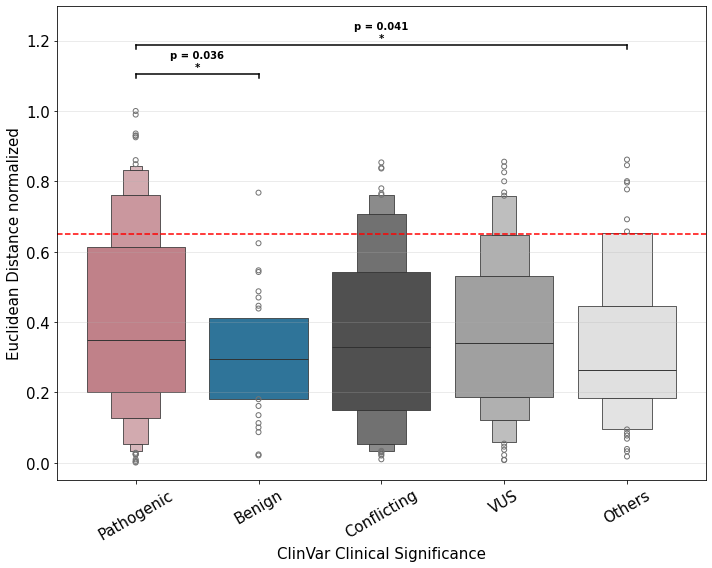

In [152]:
def add_statistical_annotations(ax, data, x_col, y_col, order=None, test='mannwhitneyu', 
                                comparisons='all_significant', y_offset_factor=0.05, 
                                fontsize=10, alpha=0.05, fdr_correction=True, fdr_method='fdr_bh'):
    """
    Add statistical significance annotations to a plot.
    
    Parameters:
    -----------
    ax : matplotlib.axes.Axes
        The axes object to add annotations to
    data : pl.DataFrame or pd.DataFrame
        DataFrame containing the data
    x_col : str
        Column name for x-axis categories
    y_col : str
        Column name for y-axis values
    order : list, optional
        Order of categories on x-axis
    test : str
        Statistical test to use ('mannwhitneyu', 'ttest', 'kruskal')
    comparisons : str or list of tuples
        'all_significant' to test all pairs and show only significant ones
        'adjacent' for adjacent pairs only
        Or list of specific pairs: [('Pathogenic', 'Benign'), ...]
    y_offset_factor : float
        Vertical offset for annotation bars as fraction of y-range
    fontsize : int
        Font size for significance stars
    alpha : float
        Significance level threshold (default: 0.05)
    fdr_correction : bool
        Whether to apply FDR correction for multiple testing (default: True)
    fdr_method : str
        FDR correction method ('fdr_bh' for Benjamini-Hochberg, 'fdr_by' for Benjamini-Yekutieli)
        
    Returns:
    --------
    dict : Dictionary with test results for each comparison
    """
    from scipy import stats as scipy_stats
    from statsmodels.stats.multitest import multipletests
    import pandas as pd
    import numpy as np
    from itertools import combinations
    
    # Convert to pandas if needed
    if hasattr(data, 'to_pandas'):
        df = data.to_pandas()
    else:
        df = data.copy()
    
    # Get order if not specified
    if order is None:
        order = df[x_col].unique().tolist()
    
    # Filter data for categories in order
    df = df[df[x_col].isin(order)].copy()
    
    # Set up comparisons
    if comparisons == 'all_significant':
        # Test all possible pairs
        all_pairs = list(combinations(order, 2))
    elif comparisons == 'adjacent':
        all_pairs = [(order[i], order[i+1]) for i in range(len(order)-1)]
    else:
        all_pairs = comparisons
    
    # Store all results
    all_results = {}
    
    # Perform tests on all pairs
    for cat1, cat2 in all_pairs:
        # Get data for each category
        data1 = df[df[x_col] == cat1][y_col].dropna()
        data2 = df[df[x_col] == cat2][y_col].dropna()
        
        if len(data1) < 2 or len(data2) < 2:
            continue
        
        # Perform statistical test
        if test == 'mannwhitneyu':
            statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')
            test_name = 'Mann-Whitney U'
        elif test == 'ttest':
            statistic, p_value = scipy_stats.ttest_ind(data1, data2)
            test_name = 't-test'
        elif test == 'kruskal':
            statistic, p_value = scipy_stats.kruskal(data1, data2)
            test_name = 'Kruskal-Wallis'
        
        # Store results
        all_results[f"{cat1}_vs_{cat2}"] = {
            'statistic': statistic,
            'p_value': p_value,
            'test': test_name,
            'n1': len(data1),
            'n2': len(data2),
            'mean1': data1.mean(),
            'mean2': data2.mean(),
            'median1': data1.median(),
            'median2': data2.median(),
            'cat1': cat1,
            'cat2': cat2
        }
    
    # Apply FDR correction if requested
    if fdr_correction and all_results:
        p_values = [v['p_value'] for v in all_results.values()]
        reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method=fdr_method)
        
        # Add adjusted p-values to results
        for (key, result), p_adj, is_reject in zip(all_results.items(), p_adjusted, reject):
            result['p_value_adjusted'] = p_adj
            result['reject_null_fdr'] = is_reject
    
    # Filter for significant results
    if comparisons == 'all_significant':
        if fdr_correction:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v.get('reject_null_fdr', False)}
        else:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v['p_value'] < alpha}
    else:
        significant_results = all_results
    
    if not significant_results:
        correction_text = " (FDR-corrected)" if fdr_correction else ""
        print(f"No significant comparisons found at alpha={alpha}{correction_text}")
        return all_results
    
    # Get y-axis limits for positioning
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min
    y_offset = y_range * y_offset_factor
    
    # Calculate max y value for starting position
    # Use the current plot top limit to ensure we clear violin tips
    current_y = y_max + y_offset
    
    # Sort comparisons by adjusted p-value if FDR, else by p-value
    sort_key = 'p_value_adjusted' if fdr_correction else 'p_value'
    sorted_comparisons = sorted(significant_results.items(), 
                               key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    # Add annotations for significant results
    for comparison_name, stats in sorted_comparisons:
        cat1 = stats['cat1']
        cat2 = stats['cat2']
        
        # Use adjusted p-value if FDR correction is applied
        p_value = stats.get('p_value_adjusted', stats['p_value']) if fdr_correction else stats['p_value']
        
        # Determine significance stars
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = f'p = {p_value:.3f}\n**'
        elif p_value < 0.05:
            sig_text = f'p = {p_value:.3f}\n*'
        else:
            continue  # Skip non-significant
        
        # Get x positions
        x1 = order.index(cat1)
        x2 = order.index(cat2)
        
        # Draw horizontal line
        ax.plot([x1, x2], [current_y, current_y], 'k-', lw=1.5)
        
        # Draw vertical ticks
        tick_height = y_offset * 0.2
        ax.plot([x1, x1], [current_y, current_y - tick_height], 'k-', lw=1.5)
        ax.plot([x2, x2], [current_y, current_y - tick_height], 'k-', lw=1.5)
        
        # Add significance text
        ax.text((x1 + x2) / 2, current_y + y_offset * 0.1, sig_text,
               ha='center', va='bottom', fontsize=fontsize, fontweight='bold')
        
        # Update y position for next comparison
        current_y += y_offset * 1.5
    
    # Adjust y-axis limit to accommodate annotations
    if sorted_comparisons:
        ax.set_ylim(y_min, current_y + y_offset * 0.5)
        
    return all_results

def print_statistical_summary(results, verbose=True, alpha=0.05, show_all=False, use_fdr=True):
    """
    Print summary of statistical test results.
    
    Parameters:
    -----------
    results : dict
        Dictionary returned by add_statistical_annotations
    verbose : bool
        Whether to print detailed output
    alpha : float
        Significance threshold for highlighting
    show_all : bool
        If True, show all comparisons; if False, show only significant ones
    use_fdr : bool
        Whether to use FDR-adjusted p-values for filtering (if available)
    """
    if not verbose:
        return
    
    # Check if FDR correction was applied
    has_fdr = any('p_value_adjusted' in v for v in results.values())
    
    # Filter results if requested
    if show_all:
        display_results = results
        title = "All Statistical Test Results"
    else:
        if has_fdr and use_fdr:
            display_results = {k: v for k, v in results.items() 
                             if v.get('reject_null_fdr', False)}
            title = f"Significant Statistical Test Results (FDR-corrected, alpha={alpha})"
        else:
            display_results = {k: v for k, v in results.items() 
                             if v['p_value'] < alpha}
            title = f"Significant Statistical Test Results (p < {alpha})"
    
    if not display_results:
        fdr_text = " (FDR-corrected)" if (has_fdr and use_fdr) else ""
        print(f"\nNo {'significant ' if not show_all else ''}results to display{fdr_text}")
        return
    
    print(f"\n{'='*80}")
    print(title)
    print(f"{'='*80}")
    print(f"Total comparisons: {len(results)}")
    
    if has_fdr:
        print(f"Significant comparisons (FDR): {sum(1 for v in results.values() if v.get('reject_null_fdr', False))}")
    print(f"Significant comparisons (unadjusted): {sum(1 for v in results.values() if v['p_value'] < alpha)}")
    print(f"{'='*80}")
    
    # Sort by adjusted p-value if available, else by p-value
    sort_key = 'p_value_adjusted' if (has_fdr and use_fdr) else 'p_value'
    sorted_results = sorted(display_results.items(), 
                           key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    for comparison, stats in sorted_results:
        cat1, cat2 = comparison.replace('_vs_', ' vs ').split(' vs ')
        print(f"\n{cat1} vs {cat2}:")
        print(f"  Test: {stats['test']}")
        print(f"  Statistic: {stats['statistic']:.4f}")
        print(f"  P-value: {stats['p_value']:.4e}")
        
        if has_fdr:
            print(f"  P-value (FDR-adjusted): {stats['p_value_adjusted']:.4e}")
            print(f"  Reject null (FDR): {stats['reject_null_fdr']}")
        
        print(f"  N1: {stats['n1']}, N2: {stats['n2']}")
        print(f"  Mean1: {stats['mean1']:.4f}, Mean2: {stats['mean2']:.4f}")
        print(f"  Median1: {stats['median1']:.4f}, Median2: {stats['median2']:.4f}")
        print(f"  Mean difference: {stats['mean1'] - stats['mean2']:.4f}")
        
        # Use adjusted p-value for significance markers if FDR is applied
        p_val = stats.get('p_value_adjusted', stats['p_value']) if (has_fdr and use_fdr) else stats['p_value']
        
        if p_val < 0.001:
            sig = "*** (highly significant)"
        elif p_val < 0.01:
            sig = "** (very significant)"
        elif p_val < 0.05:
            sig = "* (significant)"
        else:
            sig = "ns (not significant)"
        print(f"  Significance: {sig}")
    
    print(f"{'='*80}\n")
import matplotlib.pyplot as plt
import seaborn as sns

def plot_clinvar_distances(
    data,
    palette_map,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=None,
    threshold=0.65,
    threshold_label='LLR Threshold (0.678)',
    plot_type='boxenplot'
):
    """
    Plots a boxenplot of distances by ClinVar significance with statistical annotations.

    Parameters:
    - data: DataFrame containing the data.
    - palette_map: Dictionary mapping x_col categories to colors.
    - x_col: Column name for the x-axis (categorical).
    - y_col: Column name for the y-axis (numerical).
    - order: List specifying the order of categories on x-axis.
    - threshold: Y-value for the horizontal reference line.
    
    Returns:
    - ax: The matplotlib axes object.
    - results: The results from the statistical annotation function.
    """
    
    # Set default order if not provided
    if order is None:
        order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

    fig, ax = plt.subplots(figsize=(10, 8))


    if plot_type == 'boxenplot':

        # Plotting
        sns.boxenplot(
            data=data,
            x=x_col,
            y=y_col,
            order=order,
            palette=palette_map,
            ax=ax
        )
        
    elif plot_type == 'violinplot':

        # Plotting
        sns.violinplot(
            data=data,
            x=x_col,
            y=y_col,
            order=order,
            palette=palette_map,
            # inner='quartile',
            cut=0,
            ax=ax
        )

    # Statistical Annotations
    results = add_statistical_annotations(
        ax=ax,
        data=data,
        x_col=x_col,
        y_col=y_col,
        order=order,
        test='mannwhitneyu',
        comparisons='all_significant',
        alpha=0.05,
        fdr_correction=False,
        y_offset_factor=0.05
    )

    # Aesthetics
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
    ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
    ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
    
    # Threshold Line
    if threshold is not None:
        ax.axhline(y=threshold, color='red', linestyle='--', label=threshold_label)

    plt.tight_layout()
    plt.show()
    
    return ax, results

# --- Usage Example ---

# You can now call it with just the dataframe and the specific palette dictionary
ax, stats_results = plot_clinvar_distances(
    data=orf_distances, 
    palette_map=palette_dict["clinvar_clnsig_clean"],
    y_col="norm_dist_legacy_scaled"
)

In [153]:
def enrich_tracking_df(tracking_df, original_df):
    """
    Enrich tracking dataframe with symbol, ad_symbol, and aa_change columns.
    
    Parameters:
    -----------
    tracking_df : pd.DataFrame
        Tracking dataframe with unique_id
    original_df : pd.DataFrame or pl.DataFrame
        Original dataframe with metadata
        
    Returns:
    --------
    pd.DataFrame : Enriched tracking dataframe
    """
    # Convert to pandas if needed
    if hasattr(original_df, 'to_pandas'):
        df_pd = original_df.to_pandas()
    else:
        df_pd = original_df.copy()
    
    # Select relevant columns to merge
    metadata_cols = ['unique_id', 'symbol', 'ad_symbol', 'aa_change']
    
    # Only keep columns that exist
    available_cols = [col for col in metadata_cols if col in df_pd.columns]
    
    if 'unique_id' not in available_cols:
        print("Warning: unique_id not found in original dataframe")
        return tracking_df
    
    # Get unique metadata (in case of duplicates after processing)
    metadata = df_pd[available_cols].drop_duplicates(subset=['unique_id'])
    
    # Merge with tracking_df
    enriched_tracking = tracking_df.merge(
        metadata,
        on='unique_id',
        how='left',
        suffixes=('', '_new')
    )
    
    # Fill missing values
    for col in ['symbol', 'ad_symbol', 'aa_change']:
        if col not in enriched_tracking.columns and f'{col}_new' in enriched_tracking.columns:
            enriched_tracking[col] = enriched_tracking[f'{col}_new']
            enriched_tracking.drop(f'{col}_new', axis=1, inplace=True)
    
    return enriched_tracking

# Run full pipeline to get final scores

In [166]:
def run_full_pipeline(min_growth_score=min_growth_score,
                      scoring_conditions=scoring_conditions,
                      use_median=True, 
                      benign_filter=True,
                      drop_outliers=False,
                      plot_col='norm_dist_legacy_scaled',
                      manual_col='manual_score_growth_updated',
                      print_stats=True,
                      metadata='all'
                      ):
    tracking_dict = {}
    df, tracking_dict, tracking_df = load_original_dataframe(file_path=original_datafile_path, tracking_dict=tracking_dict)
    df = update_manual_scores(df)
    df, tracking_dict, tracking_df = initial_qaqc(df, tracking_dict=tracking_dict, tracking_df=tracking_df, manual_col=manual_col)
    df = metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, metadata_columns=metadata)#, metadata_columns='minimal')
    
    # Store a copy of df with metadata before splicing filter
    df_with_metadata = df.to_pandas() if hasattr(df, 'to_pandas') else df.copy()
    
    df, tracking_df = remove_splicing_variants(df, tracking_df=tracking_df)
    df, tracking_dict, tracking_df = sequencing_filtering(df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir, tracking_df=tracking_df)

    df, tracking_dict, dico, tracking_df = consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=use_median, drop_outliers=drop_outliers, tracking_df=tracking_df, manual_col=manual_col, manual_extrapolation_plates=None)
    df, tracking_dict, tracking_df = qa_qc_filtering(df, tracking_dict=tracking_dict, min_growth_score=min_growth_score, tracking_df=tracking_df)
    df, tracking_dict, tracking_df = select_best_media(df, scoring_conditions=scoring_conditions, min_growth_score=min_growth_score, verbose=False, tracking_dict=tracking_dict, benign_filter=benign_filter, tracking_df=tracking_df)
    
    # Enrich tracking_df with metadata
    tracking_df = enrich_tracking_df(tracking_df, df_with_metadata)
    
    
    orf_distances, profiles = compute_orf_distances(df)
    plot_patho_benign(scores=df, metric='log2fc', title=f"Edges - log2fc")
    plot_patho_benign(scores=orf_distances, metric=plot_col, title=f"ORF Distances - {plot_col}")
    
    ax, stats_results = plot_clinvar_distances(data=orf_distances, palette_map=palette_dict["clinvar_clnsig_clean"], y_col=plot_col)
    from scipy import stats as scipy_stats


    if print_stats:
        metric_cols = [
        "norm_dist_legacy_scaled",
        "norm_dist_rms_scaled",
        "relative_rms_dist",
        "mean_signed_difference",
        "mean_log2fc",
        "max_perturbation_normalized",
        "composite_rank_score"
        ] 
        for col in metric_cols:
            data1 = orf_distances.filter(pl.col("clinvar_clnsig_clean").is_in(["Pathogenic"]))[col].to_list()
            data2 = orf_distances.filter(pl.col("clinvar_clnsig_clean").is_in(["Benign"]))[col].to_list()

            statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')

            print(f"{col}")
            print(f"P-value: {p_value:.4e}")
            print()
        
    
    return df, orf_distances, tracking_dict, tracking_df

## New euclid (RMS), WT and dont drop outliers

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/2311983843.py:288: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['manual_correction_applied'] = df['manual_correction_applied'].fillna(False).astype(bool)


Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2229
Total unique db_orf_id: 75
Total Pathogenic variants: 947
Total Benign variants: 118


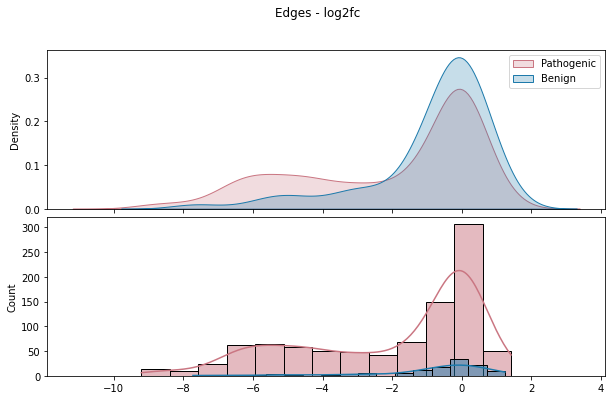

Plotting norm_dist_rms_scaled distribution for Pathogenic and Benign variants
Total variants: 506
Total unique db_orf_id: 75
Total Pathogenic variants: 250
Total Benign variants: 31


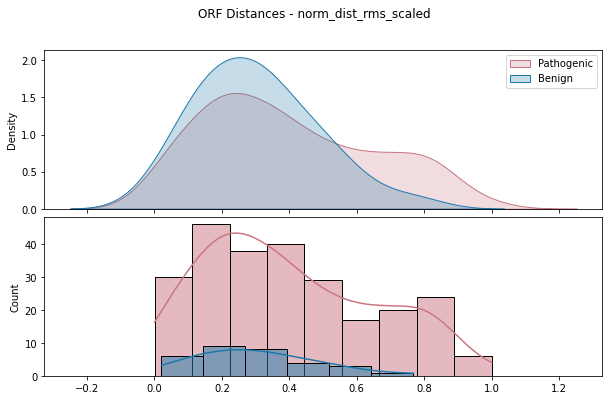

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:354: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:355: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


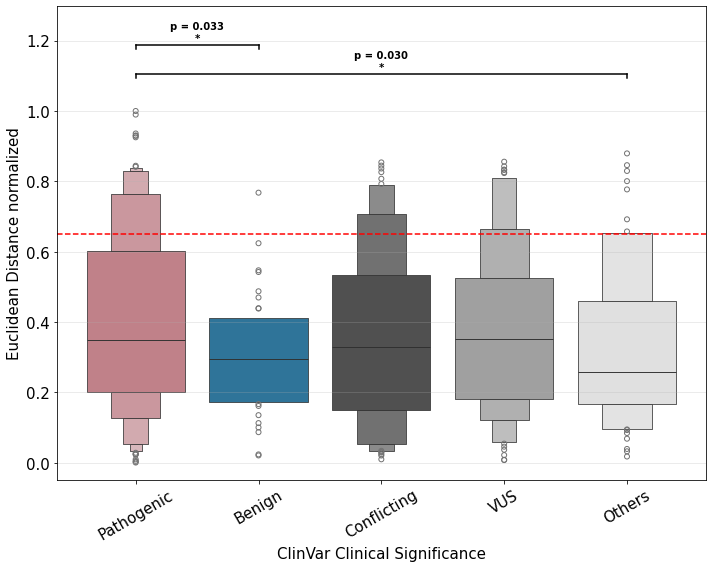

norm_dist_legacy_scaled
P-value: 3.5685e-02

norm_dist_rms_scaled
P-value: 3.3185e-02

relative_rms_dist
P-value: 1.0393e-01

mean_signed_difference
P-value: 2.8616e-02

mean_log2fc
P-value: 6.6094e-02

max_perturbation_normalized
P-value: 3.3884e-02

composite_rank_score
P-value: 4.8203e-02



In [177]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']
# scoring_conditions = ['LWH1']

df, orf_distances, tracking_dict, tracking_df = run_full_pipeline(min_growth_score=min_growth_score,
                                                           scoring_conditions=scoring_conditions,
                                                           use_median=True,
                                                           benign_filter=False,
                                                           drop_outliers=False,
                                                           plot_col='norm_dist_rms_scaled',
                                                           manual_col='manual_score_growth_updated',
                                                           )

In [168]:
df.write_csv(f'{outputs_dir}/edges_df.csv')
orf_distances.write_csv(f'{outputs_dir}/orf_distances.csv')

In [181]:
# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,…,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,str,f64,f64,str,…,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,bool,str,str,str,str,str,str,str,bool,f64,f64,f64,f64,f64,str
"""VUSAPWT1B1r04_023""","""A09""","""VUSAPWT1B1r04_019_020_021_022_…","""VUSAPWT1B1""","""r10""","""LWH10""","""1""",false,54341,null,2713,838,"""VUSMutY8Dh011""","""A09""","""CEGSint_Y8A_4""","""A12""",472.060148,3.0,917,1,288799,3.0,false,false,false,false,432879.155963,403.053218,"""PTPN3""","""MLH1""","""Ser508Arg""","""MLH1_Ser508Arg""","""NC_000003.12:37028898:T:G""","""1524T>G""",3.0,3.7028898e7,"""T""",…,"""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,93.22,24.615385,""">90""","""10-90""","""609310""","""autosomal dominant""","""GenCC""","""Rare genetic immune disease; R…",3.0,"""LYNCH SYNDROME 2""",false,"""2713.0_838.0_VUSAPWT1B1""","""2713.0_838.0_LWH10_VUSAPWT1B1""","""54341.0_2713.0_838.0_VUSAPWT1B…","""54341.0_2713.0_VUSAPWT1B1""","""1""","""1""","""Y""",false,448.189958,145.965828,3.0,328.55916,0.446788,"""MLH1_PTPN3_Ser508Arg"""
"""VUSAPWT1B2r05_039""","""M07""","""VUSAPWT1B2r05_037_038_039_040_…","""VUSAPWT1B2""","""r11""","""LWH25""","""1""",false,100011278,null,13939,204115,"""VUSMutY8Dh032""","""B10""","""CEGSint_Y8A_5""","""A05""",241.934645,0.0,559,6,135749,1.0,false,false,false,false,135241.466287,125.923153,"""KRT16""","""KRT86""","""Asn114Asp""","""KRT86_Asn114Asp""","""NC_000012.12:52302256:A:G""","""340A>G""",12.0,5.2302256e7,"""A""",…,"""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,87.71,61.1465,"""70-90""","""10-90""","""158000""","""autosomal dominant""","""OMIM""","""Rare genetic skin disease""",1.0,"""MONILETHRIX""",false,"""13939.0_204115.0_VUSAPWT1B2""","""13939.0_204115.0_LWH25_VUSAPWT…","""100011278.0_13939.0_204115.0_V…","""100011278.0_13939.0_VUSAPWT1B2""","""1""","""1""","""Y""",false,126.507445,10.522847,0.0,407.617492,-1.680169,"""KRT86_KRT16_Asn114Asp"""
"""VUSAPWT1B1r04_016""","""C23""","""VUSAPWT1B1r04_013_014_015_016_…","""VUSAPWT1B1""","""r10""","""LWH10""","""1""",false,1863,null,52920,2687,"""VUSMutY8Dh007""","""H01""","""CEGSint_Y8A_6""","""F11""",609.849701,4.0,1100,1,30093,4.0,false,false,false,false,670834.670857,624.613288,"""STAM2""","""LITAF""","""Pro34Thr""","""LITAF_Pro34Thr""","""NC_000016.10:11556631:G:T""","""100C>A""",16.0,1.1556631e7,"""G""",…,"""C (loop/coil)""",null,null,null,null,null,null,null,null,null,null,null,53.14,91.911766,"""50-70""","""$\geqslant$90""","""601098""","""autosomal dominant""","""OMIM""","""Rare genetic neurological diso…",1.0,"""CHARCOT-MARIE-TOOTH DISEASE, D…",false,"""52920.0_

In [182]:
df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
).select(['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'ad_symbol', 'ad_orf_id', 'clinvar_clnsig_clean', 'consensus_score', 'wt_consensus_score', 'log2fc']).write_csv(f"{outputs_dir}/ppi_level_scores_minimal_dacc.csv")

In [191]:
orf_distances[['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'gene_variant' ,'clinvar_clnsig_clean', 'norm_dist_rms']].write_csv(f"{outputs_dir}/orf_distances_minimal_dacc.csv")

In [197]:
# Create description files for DACC outputs

# PPI Level Scores Description
ppi_level_description = """# Column Descriptions for ppi_level_scores_minimal_dacc.csv
# sqY2H (semi-quantitative Yeast Two-Hybrid) PPI-level scores
# Generated from VarChAMP variant effect mapping pipeline

Column Name          | Description
---------------------|----------------------------------------------------------------------------
symbol               | Gene symbol (HGNC gene name) of the disease gene (DB/bait)
db_orf_id            | Database ORF identifier for the disease gene (bait)
aa_change            | Amino acid change notation (e.g., "Arg292Cys"), or NaN for wild-type reference
db_mut_id            | Mutation identifier (0 for wild-type, unique integer ID for variants)
ad_symbol            | Activation domain gene symbol - the interacting partner (AD/prey)
ad_orf_id            | Activation domain ORF identifier for the interacting partner
clinvar_clnsig_clean | Simplified ClinVar clinical significance classification:
                     |   - Pathogenic: ClinVar Pathogenic or Likely pathogenic
                     |   - Benign: ClinVar Benign or Likely benign
                     |   - VUS: Variant of Uncertain Significance
                     |   - Conflicting: Conflicting interpretations
                     |   - Others: Other classifications or missing
consensus_score      | Consensus growth score for the variant PPI (arbitrary units, 0-800 range)
                     |   - Calculated from replicate colony measurements after QC filtering
                     |   - Outlier correction applied using manual scores when needed
                     |   - Higher values indicate stronger protein-protein interaction
wt_consensus_score   | Consensus growth score for the corresponding wild-type PPI (reference)
                     |   - Same scale as consensus_score
                     |   - Used as baseline for fold-change calculations
log2fc               | Log2 fold change: log2((variant_score + 1) / (wt_score + 1))
                     |   - Negative values indicate reduced/disrupted interaction
                     |   - Positive values indicate enhanced interaction
                     |   - Values near 0 indicate no change from wild-type
"""

# ORF Distances Description
orf_distances_description = """# Column Descriptions for orf_distances_minimal_dacc.csv
# sqY2H (semi-quantitative Yeast Two-Hybrid) variant-level perturbation scores
# Aggregated across all tested interactors for each variant
# Generated from VarChAMP variant effect mapping pipeline

Column Name          | Description
---------------------|----------------------------------------------------------------------------
symbol               | Gene symbol (HGNC gene name) of the disease gene
db_orf_id            | Database ORF identifier for the disease gene
aa_change            | Amino acid change notation (e.g., "Arg292Cys")
db_mut_id            | Mutation identifier (unique integer ID for each variant)
gene_variant         | Combined gene and variant identifier (e.g., "BRCA1_Arg292Cys")
clinvar_clnsig_clean | Simplified ClinVar clinical significance classification:
                     |   - Pathogenic: ClinVar Pathogenic or Likely pathogenic
                     |   - Benign: ClinVar Benign or Likely benign
                     |   - VUS: Variant of Uncertain Significance
                     |   - Conflicting: Conflicting interpretations
                     |   - Others: Other classifications or missing
norm_dist_rms        | Normalized RMS Euclidean distance (primary PPI perturbation score)
                     |   - Measures overall disruption of the interaction profile vs wild-type
                     |   - Calculated as: sqrt(mean((variant - wt)^2)) across all interactors
                     |   - Normalized by sqrt(number of edges) for cross-gene comparability
                     |   - Higher values indicate greater disruption of protein interactions
"""

# Raw Measurements Description
raw_measurements_description = """# Column Descriptions for sqY2H_raw_measurements_assay_X_CONDITION.csv
# Raw sqY2H colony measurements before consensus score calculation
# Split by assay batch (1, 2, 3) and media condition (LW, LWH1, LWH10, LWH25)
# Generated from VarChAMP variant effect mapping pipeline

Column Name                      | Description
---------------------------------|----------------------------------------------------------------------------
scoring_pla                      | Scoring plate identifier for image tracking
scoring_pos                      | Well position on the scoring plate (1-384 for 384-well format)
retest_batch                     | Batch identifier (e.g., "VUSAPWT1B1" = Assay 1, Batch 1)
condition_name                   | Growth media condition:
                                 |   - LW: Leucine/Tryptophan dropout (mating control, no selection)
                                 |   - LWH1: LW + 1mM 3-AT (low stringency selection)
                                 |   - LWH10: LW + 10mM 3-AT (medium stringency selection)
                                 |   - LWH25: LW + 25mM 3-AT (high stringency selection)
media_control                    | Boolean flag for media-only control wells (True/False)
assay_id                         | Assay identifier extracted from retest_batch (1, 2, or 3)
db_orf_id                        | Database ORF identifier for the disease gene (bait)
db_mut_id                        | Mutation identifier (0 = wild-type, >0 = variant)
ad_orf_id                        | Activation domain ORF identifier (interactor/prey)
per_well_integrated_intensity_gray | Automated colony intensity score from image analysis
                                 |   - Integrated pixel intensity of the colony
                                 |   - Higher values = larger/denser colonies = stronger interaction
                                 |   - Range typically 0-800, values >800 flagged as outliers
total_colony_area                | Total colony area in pixels from image segmentation
                                 |   - Used for size-based quality control
                                 |   - Values >1200 flagged as potential imaging artifacts
manual_score_growth              | Manual visual scoring of colony growth (0-4 scale):
                                 |   - 0: No visible growth
                                 |   - 1: Weak/barely visible growth
                                 |   - 2: Moderate growth
                                 |   - 3: Good growth
                                 |   - 4: Strong/maximal growth
                                 |   - NaN: Contaminated well (excluded from analysis)


# File Naming Convention:
# sqY2H_raw_measurements_assay_{ASSAY}_{CONDITION}.csv
# - ASSAY: 1, 2, or 3 (experimental batch)
# - CONDITION: LW, LWH1, LWH10, or LWH25 (media stringency)

# Notes:
# - Each file contains raw replicate measurements (typically 4 replicates per PPI)
# - Consensus scores are calculated from these measurements after QC filtering
# - LW condition serves as mating efficiency control (should show growth for valid matings)
# - LWH conditions provide interaction strength readout at different stringencies
"""

# Write the files
import os

outputs_dir = "../3_outputs/sqY2H"

with open(os.path.join(outputs_dir, "ppi_level_scores_minimal_dacc_DESCRIPTION.txt"), "w") as f:
    f.write(ppi_level_description)

with open(os.path.join(outputs_dir, "orf_distances_minimal_dacc_DESCRIPTION.txt"), "w") as f:
    f.write(orf_distances_description)

with open(os.path.join(outputs_dir, "sqY2H_raw_measurements_DESCRIPTION.txt"), "w") as f:
    f.write(raw_measurements_description)

print("Description files created successfully:")
print(f"  - {outputs_dir}/ppi_level_scores_minimal_dacc_DESCRIPTION.txt")
print(f"  - {outputs_dir}/orf_distances_minimal_dacc_DESCRIPTION.txt")
print(f"  - {outputs_dir}/sqY2H_raw_measurements_DESCRIPTION.txt")

Description files created successfully:
  - ../3_outputs/sqY2H/ppi_level_scores_minimal_dacc_DESCRIPTION.txt
  - ../3_outputs/sqY2H/orf_distances_minimal_dacc_DESCRIPTION.txt
  - ../3_outputs/sqY2H/sqY2H_raw_measurements_DESCRIPTION.txt


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:327: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:354: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:355: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


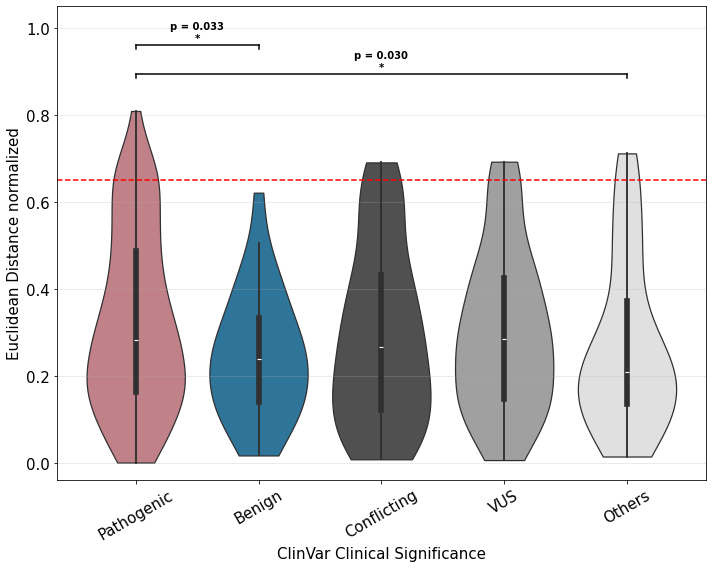

In [157]:
ax, stats_results = plot_clinvar_distances(
data=orf_distances, 
palette_map=palette_dict["clinvar_clnsig_clean"],
y_col="norm_dist_rms",
plot_type='violinplot'
)

In [158]:
tracking_df[tracking_df.aa_change == 'Arg292Cys']

,unique_id,ad_orf_id,db_orf_id,db_mut_id,condition_name,retest_batch,manual_score_growth,status,reason,symbol,ad_symbol,aa_change
3114,3114,2522.0,7652.0,1812.0,LW,VUSAPWT1B1,4.0,Dropped,sequencing_validation_failed,STXBP1,TRIM38,Arg292Cys
3115,3115,2522.0,7652.0,1812.0,LW,VUSAPWT1B1,4.0,Dropped,sequencing_validation_failed,STXBP1,TRIM38,Arg292Cys
3162,3162,2522.0,7652.0,1812.0,LW,VUSAPWT1B1,4.0,Dropped,sequencing_validation_failed,STXBP1,TRIM38,Arg292Cys
3163,3163,2522.0,7652.0,1812.0,LW,VUSAPWT1B1,4.0,Dropped,sequencing_validation_failed,STXBP1,TRIM38,Arg292Cys
3210,3210,7233.0,7652.0,1812.0,LW,VUSAPWT1B1,4.0,Dropped,sequencing_validation_failed,STXBP1,STX5,Arg292Cys
...,...,...,...,...,...,...,...,...,...,...,...,...
253630,253630,100066551.0,7652.0,1812.0,LWH25,VUSAPWT6B1,0.0,Dropped,sequencing_validation_failed,STXBP1,MAPK1,Arg292Cys
254119,254119,0.0,7652.0,1812.0,LWH25,VUSAPWT6B1,0.0,Kept,None,STXBP1,empty_ad,Arg292Cys
254120,254120,0.0,7652.0,1812.0,LWH25,VUSAPWT6B1,0.0,Kept,None,STXBP1,empty_ad,Arg292Cys
254143,254143,0.0,7652.0,1812.0,LWH25,VUSAPWT6B1,0.0,Kept,None,STXBP1,empty_ad,Arg292Cys


# Genes with 1 P and 1 B variant

Plotting norm_dist_rms_scaled distribution for Pathogenic and Benign variants
Total variants: 213
Total unique db_orf_id: 13
Total Pathogenic variants: 92
Total Benign variants: 23


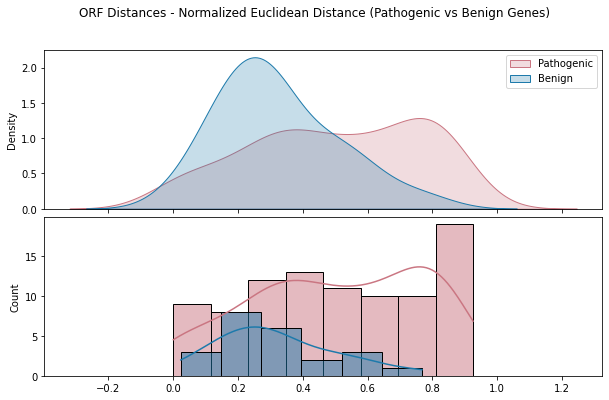

In [159]:
path_ben_genes = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign"])
    
    if has_pathogenic and has_benign:
        path_ben_genes.append(gene)
        
orf_distances_path_ben = orf_distances.filter(
    pl.col("symbol").is_in(path_ben_genes)
)

plot_patho_benign(orf_distances_path_ben, metric='norm_dist_rms_scaled', title="ORF Distances - Normalized Euclidean Distance (Pathogenic vs Benign Genes)")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:354: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/1494376601.py:355: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


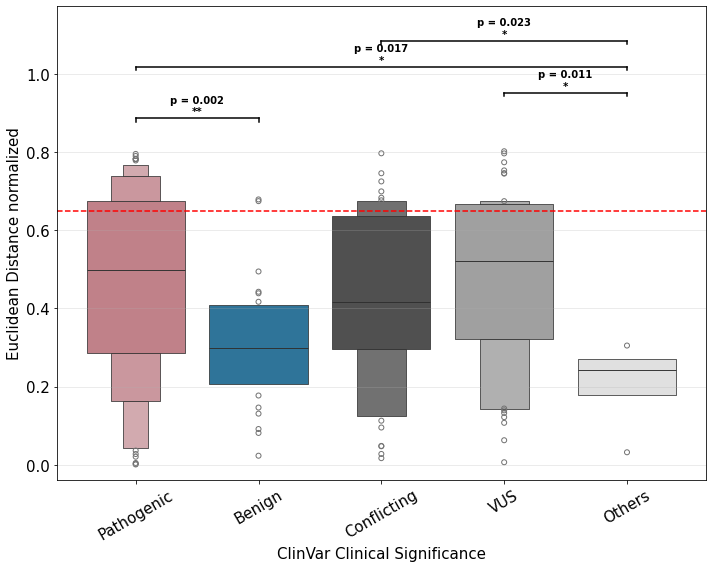

In [160]:
ax, stats_results = plot_clinvar_distances(
data=orf_distances_path_ben, 
palette_map=palette_dict["clinvar_clnsig_clean"],
y_col="max_perturbation"
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/825640049.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/825640049.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(category_labels, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/825640049.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_24491/825640049.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_tic

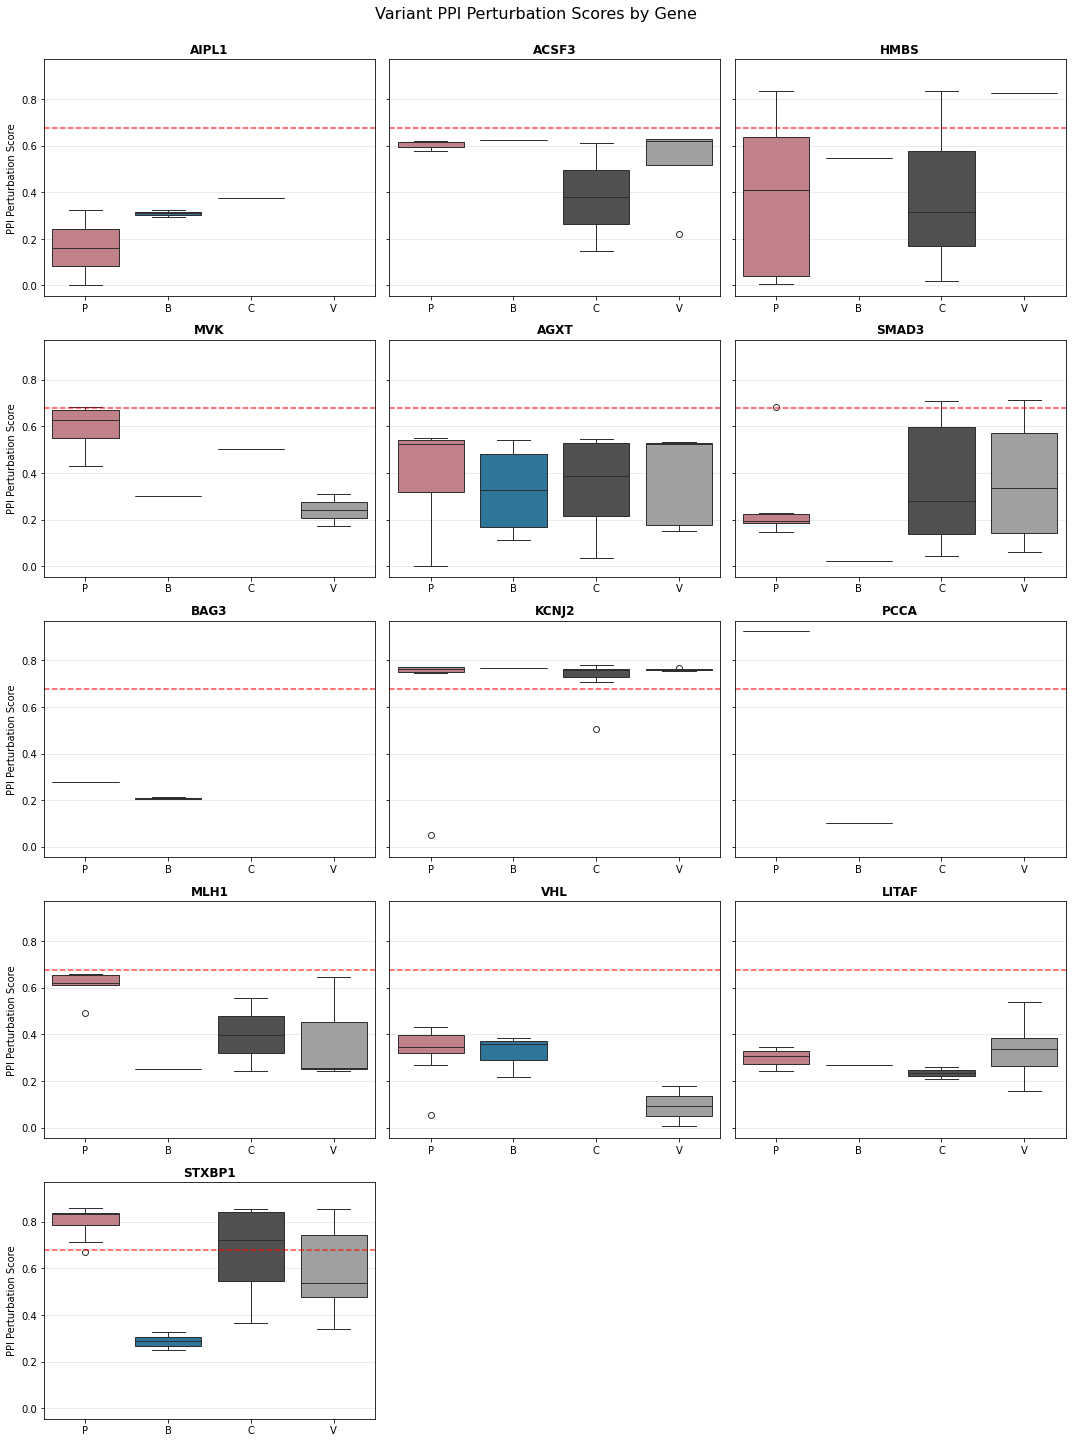

In [161]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic", "Benign", "Conflicting", "VUS"]
category_labels = ["P", "B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="norm_dist_legacy_scaled",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Set custom x-tick labels
        ax.set_xticklabels(category_labels, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")